[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/VQC_AdversarialRiskBound_Li2025.ipynb)


# A model-independent lower bound on the adversarial error of quantum classifiers: Li et al. (2025) step by step

**Paper.** Bacui Li, Tansu Alpcan, Chandra Thapa and Udaya Parampalli, *Computable Model-Independent Bounds for Adversarial Quantum Machine Learning*, IEEE Transactions on Quantum Engineering, 2025. DOI [10.1109/TQE.2025.3569922](https://doi.org/10.1109/tqe.2025.3569922), preprint arXiv:2411.06863.

**What this notebook does.** An evasion attacker perturbs a test input a little so that the classifier errs. How small can the adversarial error possibly get for a classifier that already makes a fraction `alpha` of mistakes on clean data? The paper answers with a number that depends only on the data, not on the model: the *adversarial-risk lower bound*. This notebook

1. downloads MNIST and Fashion-MNIST, shows them, and builds the paper's 10-qubit amplitude-encoded variational classifier in PennyLane;
2. implements the two attacks of the paper: classical l2 PGD and the new quantum *TD-PGD* (trace-distance PGD);
3. implements the bound estimator (sphere carving, Algorithms 1-3 with the new quantum sphere expansion of Theorem 1) and checks the theory numerically;
4. trains six models (three softmax temperatures per data set), measures their adversarial error and compares it with the bound, together with classical baselines on identical inputs;
5. prints the paper's numbers next to ours and states, claim by claim, what was reproduced.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (default in the configuration cell) is a class demo; set `False` for the larger budgets written next to every constant. Everything is an exact simulation (the paper also simulates the circuits); no quantum hardware or token is needed. MNIST and Fashion-MNIST are public, so no Hugging Face token is required; if you have one, store it as the Colab secret `HF_TOKEN`.

**What you get at the end.** The data and circuit figures, a table analogous to the paper's Table 1 (adversarial error versus estimated bound for six models and two attacks), the paper's Table 2 ratios, training trajectories above the bound curve, and a final table with one verdict per claim.


## The paper in one page

**Problem.** Adversarial error (the share of test inputs that a bounded perturbation can flip) is the usual robustness metric for QML, but a number such as "62% adversarial error" says little unless we know what is achievable at all. Part of the error is unavoidable because of the *geometry of the data*: when many inputs of different classes lie close together, some will be misclassified after a small push, whatever the model.

**Decision.** For a classifier with clean error `alpha` and an attacker of strength `eps`, the paper computes a lower bound `c_adv(alpha, eps)` on the adversarial risk that holds for *any* classifier, classical or quantum, with that clean error. A model whose adversarial error is close to the bound is as robust as the data allow.

**Method.**
* Adversarial risk of a classifier f = measure of the `eps`-expansion of its error region E (Eqs. 9-11). The bound is the minimum of `mu(E_eps)` over all error regions with `mu(E) = alpha` (Eq. 12).
* The minimisation is solved heuristically: E is a union of T = 20 hyper-spheres centred on samples and grown greedily to the pair (centre, size) that adds the fewest extra samples to the expansion (Algorithm 1, with a sorted-distance trick that makes the search parallel, Algorithm 2).
* Because the regions are fitted on a training half, the risks measured on the test half differ from the target; Algorithm 3 therefore repeats the search for m = 10 target error rates in [alpha, 1.1 alpha] on random partitions and regresses the test adversarial risk on the test clean risk, evaluating the line at `alpha`.
* *Classical attack:* l2 distance between pixel vectors; a sphere of radius r expands to r + eps.
* *Quantum attack:* the adversary changes the encoded quantum state `|psi>` by up to `eps` in trace distance (the certification radius of state verification). For pure states trace distance = sin(Bures angle), distances between amplitude-encoded images are `sqrt(1 - cos^2)` (Eq. 29), and Theorem 1 shows that a sphere of radius r expands to r' = r sqrt(1-eps^2) + eps sqrt(1-r^2).
* *Attacks used to test the bound:* l2 PGD with gradients of the simulated circuit, and TD-PGD, a PGD whose step follows the gradient on the unit sphere of amplitudes and whose projection clips the Bures angle (Fig. 4).

**Data and models.** MNIST and Fashion-MNIST, 10 classes, 784 pixels. Model: 10 qubits, amplitude encoding of the 784 pixels (padded to 1024), 200 layers of `StronglyEntanglingLayers` with CZ gates (6,000 parameters), `<Z_i>` of the 10 qubits as class scores, softmax with temperature t = 1, 1/10, 1/20 (models M1-M3 and F1-F3), 5 epochs of 30 batches of 2,000 images. Attacks: l2 with eps = 100/255 and TD with eps = 0.1; adversarial error from 2,500 test images.

**Claims to test.**
1. In all 12 (model, attack) cells of Table 1 the measured adversarial error is above the estimated bound (e.g. M3: 0.140 vs 0.082 for l2, 0.564 vs 0.084 for TD).
2. In the best case the adversarial error is only about 10% above the bound (Table 2: ratio 1.09 for F2 under l2).
3. During training the (clean error, adversarial error) trajectory never crosses the bound curve (Fig. 6, 8).
4. The ratio adversarial error / bound grows as the softmax temperature falls (Table 2), with the single exception F2 under l2.
5. Theorem 1 and the Bures-angle triangle inequality (Appendix A) are true.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Quantum model | 10 qubits, amplitude encoding, 200 `StronglyEntanglingLayers` (CZ), `<Z_i>` read-out | Same circuit, **fewer layers** (`N_LAYERS`, 4 in FAST, 10 in the full run): a CPU simulator cannot train 200 layers x 10 qubits on 2,000-image batches |
| Training | 5 epochs x 30 batches x 2,000 images, "lower learning rate for lower temperature" | `TRAIN_STEPS` Adam steps on `BATCH_SIZE` images; learning rates `LEARNING_RATES` and N(0, 0.1^2) initial weights are `# CHOICE:` (not given) |
| Pixel scale | not stated | pixels in [0, 1]; l2 distances and eps = 100/255 refer to this scale `# CHOICE:` |
| l2 attack | PGD, eps = 100/255, number of steps not given | `PGD_STEPS` steps of size 2.5 eps/steps, projection on the l2 ball, pixels clipped to [0, 1] `# CHOICE:` |
| Quantum attack | TD-PGD, eps = 0.1 (trace distance), steps not given | Same attack on the 784 real amplitudes (padding stays 0, so the adversarial state stays inside the encoding manifold), geodesic step of 2.5 theta_eps/steps `# CHOICE:` |
| Attacker's softmax | "t to 150" in the PDF text (a lost fraction bar, see the "110", "120" of Table 2) | t = 1/50 for the attacker's gradient `# CHOICE:` |
| Adversarial error sample | 2,500 test images (250 per class) | `N_ADV` class-balanced test images; the binomial standard deviation is printed |
| Bound: sample | not stated | `N_BOUND` random images from the 70,000 of train + test, random 50/50 partition per run `# CHOICE:` |
| Bound: hyper-parameters | T = 20, m = 10, [alpha, 1.1 alpha], all samples are candidate centres | T = `N_SPHERES`, m = `M_ITERS`; **`N_CAND` random candidate centres per sphere** (GPU-free speed-up) `# CHOICE:`; additionally a *calibrated* alpha range (see below) |
| Hardware | simulation only | exact simulation only; `IBM_TOKEN` is unused |
| Classical baselines | not in the paper | logistic regression, MLP, random forest and RBF-SVC on the same unit-norm vectors, attacked with the same PGD attacks (RF and SVC by transfer) |

*Why a calibrated range?* The search fits its spheres on the training half, so on the test half the clean risk is smaller than the target `alpha_nu` (the spheres are over-fitted). With the literal range [alpha, 1.1 alpha] the regression then has to extrapolate. The paper says the range is adjusted until alpha is covered by the measured test risks; the notebook therefore reports both the literal and a calibrated range (pilot run to measure the shrinkage, then a range that brackets alpha).


## 0. Setup

The first cell installs PennyLane when it is missing (Colab); torch, numpy, pandas, scikit-learn and matplotlib are preinstalled. The second cell holds every constant. The third imports, fixes seeds and prints library versions.


In [1]:
# Versions tested with this notebook (October 2026). Colab already ships torch, numpy, pandas, scikit-learn, matplotlib,
# pyarrow and huggingface_hub. The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" pyarrow huggingface_hub
    if importlib.util.find_spec("torch") is None:
        %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")


PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False            # True: class demo (a few minutes). False: the larger budgets listed in the right-hand comments.

SEED = 42                   # CHOICE: the paper gives no seed. Controls data subsets, weight initialisation, batching, bound partitions.
DATA_DIR = "qml_data"       # downloads are cached here (relative to the working directory; never inside a git repo)
IBM_TOKEN = ""              # unused: the whole study is an exact simulation (the paper simulates the circuits as well)

# --- data (paper: MNIST and Fashion-MNIST, 10 classes, 784 pixels) ---
DATASETS = ["mnist", "fashion"]
TRAIN_POOL   = 6000 if FAST_MODE else 20000     # training images drawn from the 60,000 training images (paper: all of them)
N_TEST_CLEAN = 500  if FAST_MODE else 2000      # test images for the non-adversarial error (paper: 10,000)
N_ADV        = 100  if FAST_MODE else 300       # test images for the adversarial error, class balanced (paper: 2,500 = 250 per class)

# --- quantum model: 10 qubits, amplitude encoding, StronglyEntanglingLayers with CZ, <Z_i> read-out (paper Fig. 3) ---
N_QUBITS = 10               # paper: 10 qubits, one per class
N_LAYERS = 4 if FAST_MODE else 10               # paper: 200 layers (6,000 parameters). CHOICE: far fewer layers, a CPU simulator cannot afford 200
TEMPERATURES = [1.0, 0.1, 0.05]                 # paper: softmax temperature t = 1, 1/10, 1/20 for models M1/M2/M3 and F1/F2/F3
LEARNING_RATES = {1.0: 0.1, 0.1: 0.1, 0.05: 0.05}     # CHOICE: Adam, cosine decay to 0; the paper only says "lower learning rate for lower temperature"
INIT_SD = 0.3               # CHOICE: weights ~ N(0, 0.3^2) (paper: unspecified)
BATCH_SIZE = 150 if FAST_MODE else 300          # paper: 2,000 images per batch
TRAIN_STEPS = 30 if FAST_MODE else 120          # paper: 5 epochs x 30 batches = 150 steps
CHECK_EVERY = 10 if FAST_MODE else 20           # trajectory checkpoints (paper: batches 10, 20, ..., 150)

# --- attacks ---
EPS_L2 = 100 / 255          # paper: classical l2 PGD, strength 100/255 (images scaled to [0, 1])
EPS_TD = 0.1                # paper: quantum TD-PGD, trace-distance strength 0.1
PGD_STEPS = 6 if FAST_MODE else 10              # CHOICE: the paper does not give the number of PGD iterations
T_ATTACK = 1 / 50           # paper: the attacker differentiates a model with a sharper softmax (t = 1/50; the PDF text reads "150")

# --- adversarial-risk bound (paper Sec. IV and Appendix B/C) ---
N_BOUND      = 1200 if FAST_MODE else 2400      # images the bound is estimated on (paper: not stated; GPU-sized)
N_SPHERES    = 10   if FAST_MODE else 20        # T, number of hyper-spheres (paper: 20)
M_ITERS      = 4    if FAST_MODE else 8         # m, random partitions / target error rates per estimate (paper: 10)
N_CAND       = 200  if FAST_MODE else 400       # CHOICE: random candidate centres per sphere (paper: all samples, on a GPU)
CURVE_POINTS = 3    if FAST_MODE else 5         # error rates on which the bound curve of the trajectory plots is evaluated
M_CURVE      = 3    if FAST_MODE else 4         # m used for those curve points
N_BASELINE_TRAIN = 3000 if FAST_MODE else 8000  # training images of the classical baselines (RF / SVC)
N_THREADS = 3               # torch CPU threads (shared machine)


In [3]:
import os, io, time, math, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scipy
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import torch, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

torch.set_num_threads(N_THREADS)
np.random.seed(SEED); torch.manual_seed(SEED)
RNG = np.random.default_rng(SEED)
qml.numpy.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T0 = time.time()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)

# Hugging Face token: MNIST and Fashion-MNIST are public, so none is needed. If you have one, put it in Colab Secrets as HF_TOKEN
# (or in the HF_TOKEN environment variable); it is only passed to the download call and never printed or stored.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
print("FAST_MODE =", FAST_MODE, "| layers =", N_LAYERS, "| train steps =", TRAIN_STEPS)


python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | torch 2.14.1+cpu | pennylane 0.45.1 | sklearn 1.9.1 | pandas 3.0.6
FAST_MODE = False | layers = 10 | train steps = 120


## 1. Data: MNIST and Fashion-MNIST

Both data sets are public (60,000 training and 10,000 test images of 28 x 28 grey pixels, 10 classes). The images are downloaded from Hugging Face parquet mirrors (OpenML as fallback), cached in `DATA_DIR`, and scaled to [0, 1]. From them we draw the subsets used later: a training pool, a clean test set, and a class-balanced test subset on which adversarial errors are measured (the attacks need gradients of a simulated circuit, so this set is smaller than the clean one, as in the paper).


In [4]:
INFO = {
    "mnist":   dict(repo="ylecun/mnist", sub="mnist", openml="mnist_784", title="MNIST",
                    names=[str(i) for i in range(10)]),
    "fashion": dict(repo="zalando-datasets/fashion_mnist", sub="fashion_mnist", openml="Fashion-MNIST", title="Fashion-MNIST",
                    names=["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]),
}

def _from_hub(cfg):
    from huggingface_hub import hf_hub_download
    from PIL import Image
    out = {}
    for sp in ["train", "test"]:
        p = hf_hub_download(cfg["repo"], f"{cfg['sub']}/{sp}-00000-of-00001.parquet", repo_type="dataset",
                            local_dir=os.path.join(DATA_DIR, "hub"), token=HF_TOKEN)
        df = pd.read_parquet(p)
        X = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]).astype(np.uint8)
        out[sp] = (X, df["label"].values.astype(np.int64))
    return out

def _from_openml(cfg):
    from sklearn.datasets import fetch_openml
    Xo, yo = fetch_openml(cfg["openml"], version=1, as_frame=False, return_X_y=True, data_home=os.path.join(DATA_DIR, "openml"))
    X = Xo.reshape(-1, 28, 28).astype(np.uint8); y = yo.astype(np.int64)
    return {"train": (X[:60000], y[:60000]), "test": (X[60000:], y[60000:])}

def load_raw(key):
    """Public Hugging Face parquet mirrors (OpenML as fallback); cached as .npz in DATA_DIR. Pixels scaled to [0, 1]."""
    f = os.path.join(DATA_DIR, key + "_raw.npz")
    if not os.path.exists(f):
        cfg = INFO[key]
        try:
            d = _from_hub(cfg)
        except Exception as e:
            print("hub download failed (", type(e).__name__, "), trying OpenML")
            d = _from_openml(cfg)
        np.savez_compressed(f, xtr=d["train"][0], ytr=d["train"][1], xte=d["test"][0], yte=d["test"][1])
    z = np.load(f)
    return (z["xtr"].reshape(-1, 784).astype(np.float32) / 255., z["ytr"],
            z["xte"].reshape(-1, 784).astype(np.float32) / 255., z["yte"])

RAW = {k: load_raw(k) for k in DATASETS}
for k, (xtr, ytr, xte, yte) in RAW.items():
    print(f"{INFO[k]['title']:14s} train {xtr.shape}  test {xte.shape}  pixel range [{xtr.min():.0f}, {xtr.max():.0f}]")

def balanced_idx(y, n_total, rng):
    """n_total indices with the same number of images per class (n_total / 10)."""
    per = n_total // 10
    return np.concatenate([rng.permutation(np.where(y == c)[0])[:per] for c in range(10)])

SPLIT = {}                                           # per dataset: the subsets every later section uses
for k in DATASETS:
    xtr, ytr, xte, yte = RAW[k]
    r = np.random.default_rng(SEED)
    itr = r.permutation(len(xtr))[:TRAIN_POOL]
    ite = r.permutation(len(xte))[:N_TEST_CLEAN]
    iadv = balanced_idx(yte, N_ADV, r)
    SPLIT[k] = dict(xtr=xtr[itr], ytr=ytr[itr], xte=xte[ite], yte=yte[ite], xadv=xte[iadv], yadv=yte[iadv])
print({k: {a: v.shape for a, v in d.items() if a.startswith("x")} for k, d in SPLIT.items()})


mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

fashion_mnist/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 30.9MB            

fashion_mnist/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

fashion_mnist/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 5.18MB            

fashion_mnist/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

MNIST          train (60000, 784)  test (10000, 784)  pixel range [0, 1]
Fashion-MNIST  train (60000, 784)  test (10000, 784)  pixel range [0, 1]


{'mnist': {'xtr': (20000, 784), 'xte': (2000, 784), 'xadv': (300, 784)}, 'fashion': {'xtr': (20000, 784), 'xte': (2000, 784), 'xadv': (300, 784)}}


## Dataset Exploration and Visualisation

Before anything is trained we look at the real data: shapes, feature names, the original label values and class counts, example images, a bar chart of the real classes, and two 2-D scatter plots in which **every point is one real test image coloured by its ground-truth label**. The PCA is fitted on training images only. The first scatter uses raw pixels; the second uses the unit-norm vectors `x/||x||` that the amplitude encoding stores in the 10-qubit state (this model has no angle encoding, so there is no [0, pi] scaling to show). Classes that overlap in these plots are exactly where small perturbations change the label, which is what the bound measures.


=== MNIST ===
train images (60000, 784) | test images (10000, 784) | features: 784 pixels pixel_0 ... pixel_783 (28 x 28 grey levels in [0, 1])
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


,0,1,2,3,4,5,6,7,8,9
class,0,1,2,3,4,5,6,7,8,9
train,5923,6742,5958,6131,5842,5421,5918,6265,5851,5949
test,980,1135,1032,1010,982,892,958,1028,974,1009


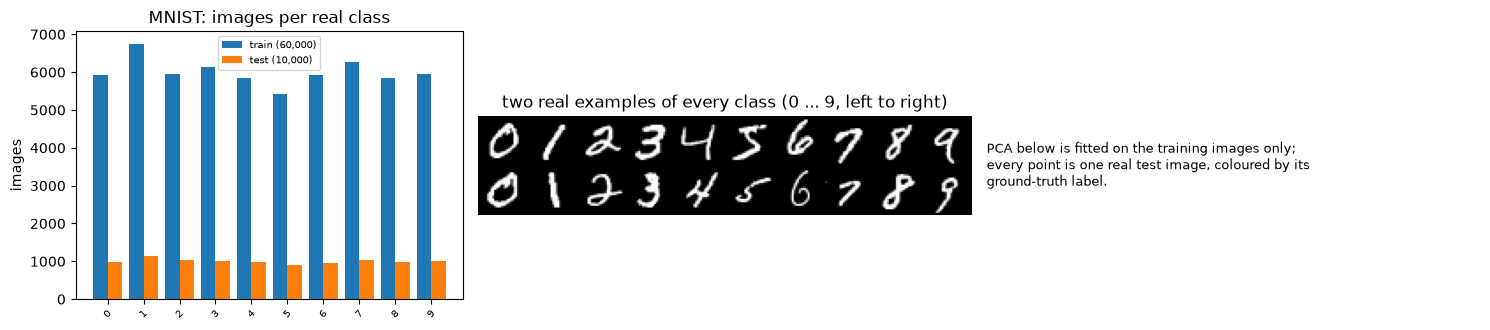

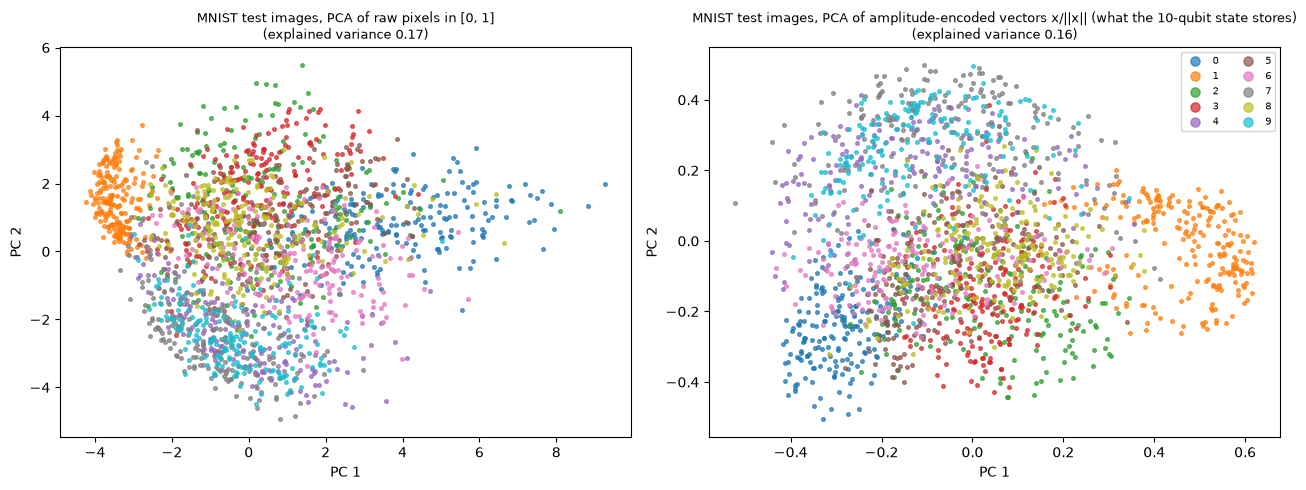

=== Fashion-MNIST ===
train images (60000, 784) | test images (10000, 784) | features: 784 pixels pixel_0 ... pixel_783 (28 x 28 grey levels in [0, 1])
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


,0,1,2,3,4,5,6,7,8,9
class,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
train,6000,6000,6000,6000,6000,6000,6000,6000,6000,6000
test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


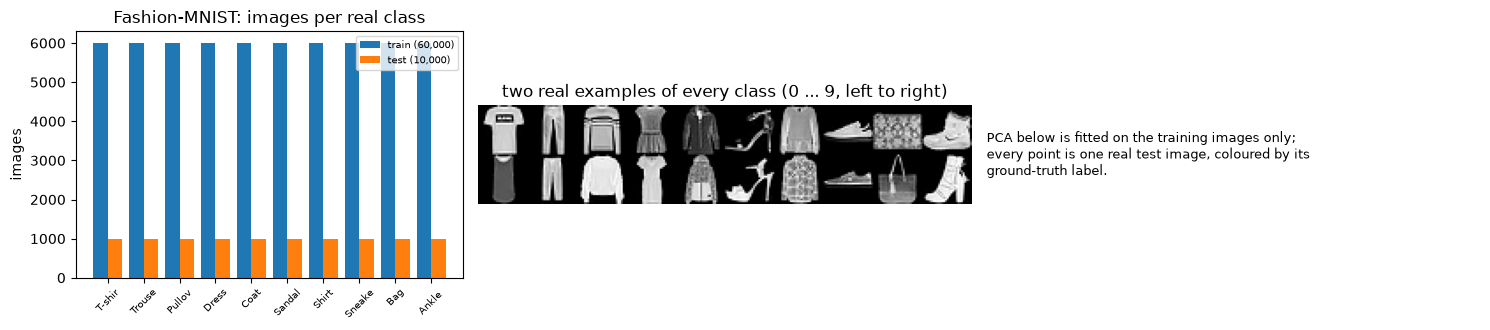

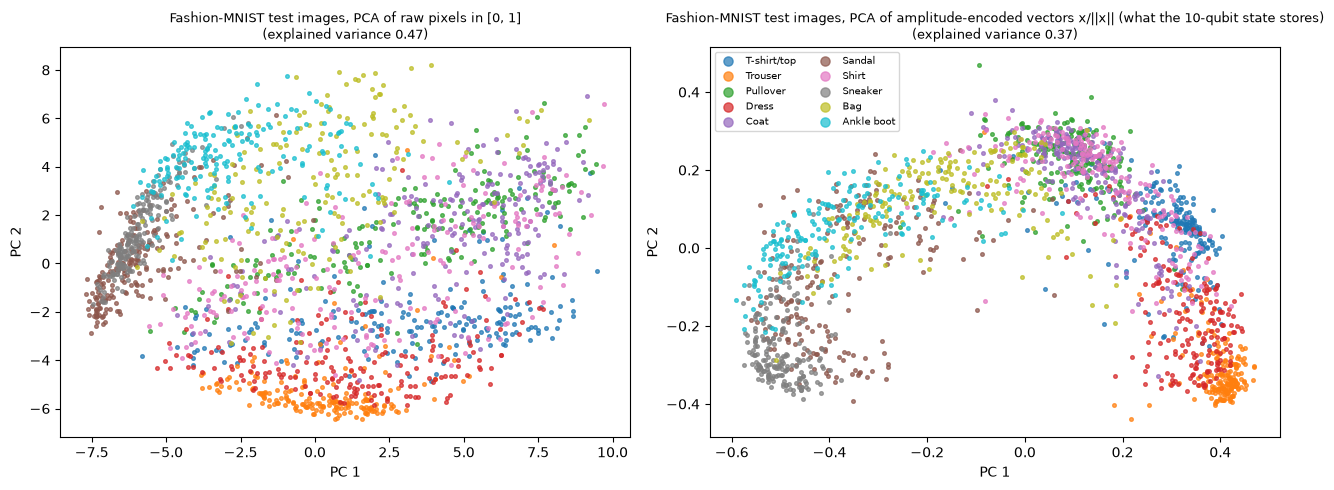

In [5]:
def vis_dataset(key):
    """Shape, feature names, label values, class counts, example images, class bar chart and two labelled PCA scatters."""
    info = INFO[key]; xtr, ytr, xte, yte = RAW[key]
    print(f"=== {info['title']} ===")
    print("train images", xtr.shape, "| test images", xte.shape, "| features: 784 pixels pixel_0 ... pixel_783 (28 x 28 grey levels in [0, 1])")
    print("original label values:", sorted(np.unique(ytr).tolist()), "->", info["names"])
    cnt = pd.DataFrame({"class": info["names"], "train": np.bincount(ytr, minlength=10), "test": np.bincount(yte, minlength=10)})
    display(cnt.T)

    fig = plt.figure(figsize=(15, 3.4))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1.4, 1.4])
    ax = fig.add_subplot(gs[0]); w = 0.4
    ax.bar(np.arange(10) - w / 2, cnt["train"], w, label="train (60,000)"); ax.bar(np.arange(10) + w / 2, cnt["test"], w, label="test (10,000)")
    ax.set_xticks(range(10)); ax.set_xticklabels([n[:6] for n in info["names"]], rotation=45, fontsize=7)
    ax.set_title(f"{info['title']}: images per real class"); ax.set_ylabel("images"); ax.legend(fontsize=7)
    # one example image per class
    ax = fig.add_subplot(gs[1]); ex = np.concatenate([np.concatenate([xtr[np.where(ytr == c)[0][j]].reshape(28, 28) for c in range(10)], 1)
                                                          for j in range(2)], 0)
    ax.imshow(ex, cmap="gray"); ax.set_axis_off(); ax.set_title("two real examples of every class (0 ... 9, left to right)")
    ax = fig.add_subplot(gs[2]); ax.set_axis_off()
    ax.text(0, 0.5, "PCA below is fitted on the training images only;\nevery point is one real test image, coloured by its\nground-truth label.", fontsize=9, va="center")
    plt.tight_layout(); plt.show()

    # PCA on the training split, test points projected: (a) raw pixels, (b) the amplitude-encoded (unit-norm) vectors the circuit receives
    rr = np.random.default_rng(SEED)
    a = rr.permutation(len(xtr))[:5000]; b = rr.permutation(len(xte))[:2000]
    fig, axs = plt.subplots(1, 2, figsize=(13, 5))
    for ax, (name, f) in zip(axs, [("raw pixels in [0, 1]", lambda X: X),
                                    ("amplitude-encoded vectors x/||x|| (what the 10-qubit state stores)", lambda X: X / np.linalg.norm(X, axis=1, keepdims=True))]):
        pca = PCA(n_components=2, random_state=SEED).fit(f(xtr[a]))
        Z = pca.transform(f(xte[b])); lab = yte[b]
        for c in range(10):
            m = lab == c
            ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.7, color=plt.cm.tab10(c), label=info["names"][c])
        ax.set_title(f"{info['title']} test images, PCA of {name}\n(explained variance {pca.explained_variance_ratio_.sum():.2f})", fontsize=9)
        ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
    axs[1].legend(markerscale=2.5, fontsize=7, ncol=2, loc="best")
    plt.tight_layout(); plt.show()

for k in DATASETS:
    vis_dataset(k)


## Quantum Circuit Architecture

The classifier of the paper (Fig. 3) as a PennyLane QNode: `AmplitudeEmbedding` of the 784 normalised pixels into 10 qubits (padded with zeros to 1024 amplitudes), then `StronglyEntanglingLayers` with CZ as the two-qubit gate (layer l applies a general 3-angle rotation `Rot` on every qubit and then CZ gates on the pairs (i, i + r mod 10) with shift r = l mod 9 + 1, which is the paper's "jth layer entangles (i, i + j mod M)"), and finally the expectation `<Z_i>` of every qubit as the score of class i. We draw the QNode that is actually executed twice: once with the templates as boxes and once unrolled into gates. The number of layers is `N_LAYERS` (the paper uses 200; the drawing and all counts below use the number the notebook trains).


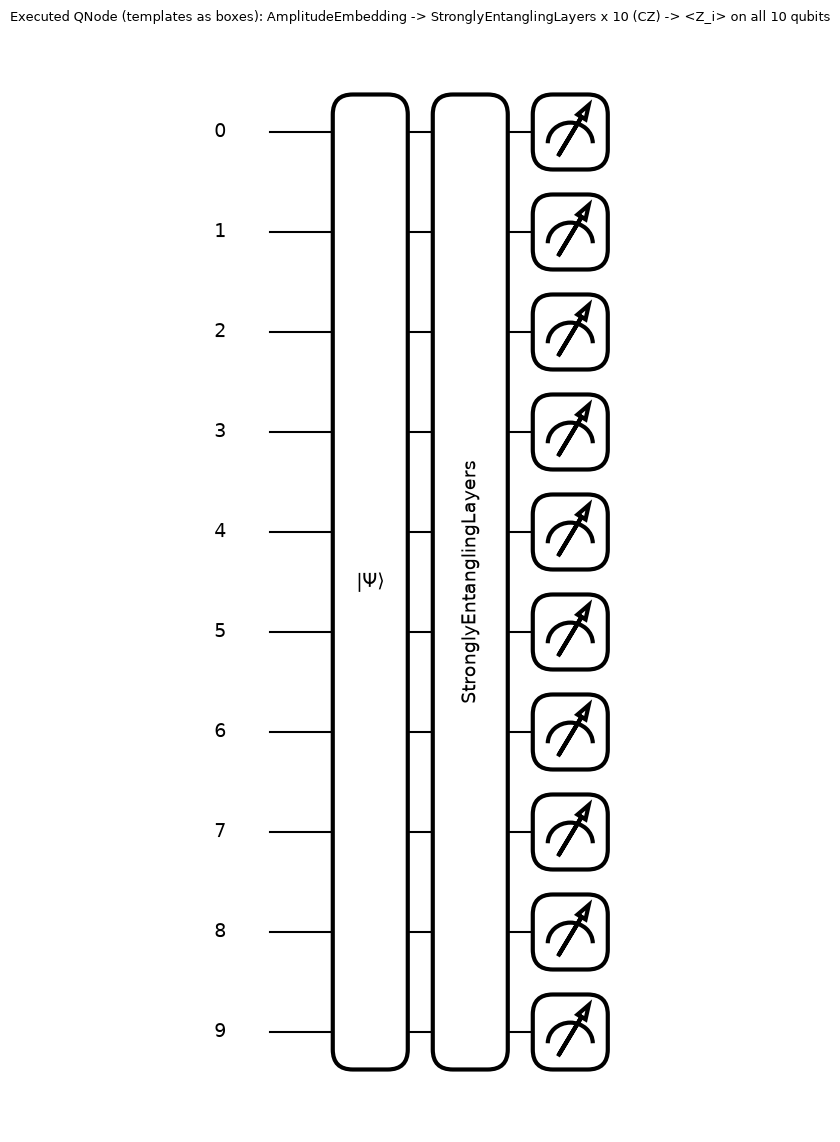



In [6]:
# ---- the circuit exactly as the paper's Fig. 3 describes it, as a PennyLane QNode ----
dev = qml.device("default.qubit", wires=N_QUBITS)

def qvc_circuit(x, w):
    """x: (784,) or (B, 784) pixels; w: (N_LAYERS, N_QUBITS, 3) rotation angles."""
    qml.AmplitudeEmbedding(x, wires=range(N_QUBITS), pad_with=0.0, normalize=True)      # 784 amplitudes padded with zeros to 2^10 = 1024
    qml.StronglyEntanglingLayers(w, wires=range(N_QUBITS), imprimitive=qml.CZ)           # layer l: Rot on every qubit, then CZ(i, i + r_l mod 10)
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]                           # 10 outputs <Z_i>, one per class

qvc = qml.QNode(qvc_circuit, dev, interface="torch", diff_method="backprop")

x_demo = torch.tensor(SPLIT["mnist"]["xte"][0], dtype=torch.float64)
w_demo = torch.zeros(N_LAYERS, N_QUBITS, 3, dtype=torch.float64)

# 1) the executed object, with PennyLane's templates drawn as boxes
fig, ax = qml.draw_mpl(qvc, level="top", style="black_white")(x_demo, w_demo)
fig.suptitle(f"Executed QNode (templates as boxes): AmplitudeEmbedding -> StronglyEntanglingLayers x {N_LAYERS} (CZ) -> <Z_i> on all 10 qubits", y=1.02, fontsize=9)
plt.show()

# 2) the same QNode with the rotation template unrolled into Rot and CZ gates (AmplitudeEmbedding kept as one state preparation)
unrolled = qml.transforms.decompose(qvc, gate_set={"Rot", "CZ", "AmplitudeEmbedding", "PauliZ"})
fig, ax = qml.draw_mpl(unrolled, style="black_white", fontsize=9)(x_demo, w_demo)
fig.suptitle(f"The same QNode unrolled to gates: {N_LAYERS} layers of (Rot on 10 qubits, then a ring of 10 CZ with shift r = l mod 9 + 1)", y=1.02, fontsize=9)
plt.show()


In [7]:
# ---- circuit facts: qubits, depth, parameters ----
tape = qml.workflow.construct_batch(unrolled, level="user")(x_demo, w_demo)[0][0]
ops = [o for o in tape.operations if o.name != "AmplitudeEmbedding"]
gate_counts = pd.Series([o.name for o in ops]).value_counts().to_dict()

# depth of the variational part (state preparation excluded): greedy ASAP schedule over wires
busy = {q: 0 for q in range(N_QUBITS)}
for o in ops:
    t = max(busy[w] for w in o.wires) + 1
    for w in o.wires: busy[w] = t
depth = max(busy.values())
n_params = int(w_demo.numel())
print(f"qubits            : {N_QUBITS}  (2^{N_QUBITS} = {2**N_QUBITS} amplitudes; 784 pixel amplitudes + 240 zero padding)")
print(f"variational layers: {N_LAYERS}  (paper: 200)")
print(f"gates (no encoding): {gate_counts}")
print(f"circuit depth     : {depth}  (variational part, state preparation not counted)")
print(f"trainable params  : {n_params} = {N_LAYERS} layers x {N_QUBITS} qubits x 3 Rot angles  (paper: 200 x 10 x 3 = 6,000)")
print("CZ ring shifts per layer:", [(l % (N_QUBITS - 1)) + 1 for l in range(N_LAYERS)], "(the paper's 'jth layer entangles (i, i+j mod M)')")
print("measurement       : <Z_i> of every qubit i = 0..9 -> 10 class scores, softmax with temperature t, argmax at test time")
print(f"assumptions       : the paper draws general u3 gates; PennyLane's Rot(phi, theta, omega) is the same 3-parameter family. Weight init is not given (CHOICE N(0, {INIT_SD}^2)).")


qubits            : 10  (2^10 = 1024 amplitudes; 784 pixel amplitudes + 240 zero padding)
variational layers: 10  (paper: 200)
gates (no encoding): {'Rot': 100, 'CZ': 100}
circuit depth     : 57  (variational part, state preparation not counted)
trainable params  : 300 = 10 layers x 10 qubits x 3 Rot angles  (paper: 200 x 10 x 3 = 6,000)
CZ ring shifts per layer: [1, 2, 3, 4, 5, 6, 7, 8, 9, 1] (the paper's 'jth layer entangles (i, i+j mod M)')
measurement       : <Z_i> of every qubit i = 0..9 -> 10 class scores, softmax with temperature t, argmax at test time
assumptions       : the paper draws general u3 gates; PennyLane's Rot(phi, theta, omega) is the same 3-parameter family. Weight init is not given (CHOICE N(0, 0.3^2)).


### A fast exact simulator, checked against the QNode

Training and attacking need thousands of forward and backward passes. PennyLane's `default.qubit` with `backprop` works but is slow for 150-image batches, so the notebook uses a batched torch statevector simulator that applies, per layer, the Kronecker product of the ten `Rot` matrices (as two 32 x 32 blocks) and the CZ ring (a diagonal of +-1). It implements exactly the same unitary; the cell compares its `<Z_i>` with the QNode on real images with random weights, and a later cell repeats the test with the trained weights of every model.


In [8]:
# ---- fast exact simulator used for training and attacks (differentiable, batched), checked against the QNode above ----
DIM = 2 ** N_QUBITS
_idx = torch.arange(DIM)
_bits = [((_idx >> (N_QUBITS - 1 - q)) & 1) for q in range(N_QUBITS)]           # qubit 0 is the most significant bit (PennyLane convention)
ZMAT = torch.stack([1 - 2 * b for b in _bits], 1).double()                     # (1024, 10): eigenvalue of Z_q on basis state |b>

def cz_signs(n_layers):
    """Diagonal +-1 vector of the CZ ring of every layer: ring r = l mod (n-1) + 1, CZ(i, (i + r) mod n) for i = 0..n-1."""
    out = []
    for l in range(n_layers):
        r = (l % (N_QUBITS - 1)) + 1
        ph = torch.zeros(DIM, dtype=torch.long)
        for i in range(N_QUBITS):
            ph += _bits[i] * _bits[(i + r) % N_QUBITS]
        out.append((1 - 2 * (ph % 2)).double())
    return out
SIGNS = cz_signs(max(N_LAYERS, 16))

def rot_mats(w, cdtype):
    """qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) as 2x2 matrices; w: (..., 3) -> (..., 2, 2)."""
    phi, th, om = w[..., 0], w[..., 1], w[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    e1 = torch.exp(-0.5j * (phi + om).to(cdtype)); e2 = torch.exp(0.5j * (phi - om).to(cdtype))
    return torch.stack([torch.stack([e1 * c, -e2 * s], -1), torch.stack([e2.conj() * s, e1.conj() * c], -1)], -2)

def _kron(ms):
    K = ms[0]
    for m in ms[1:]: K = torch.kron(K, m)
    return K

def sim_expvals(x, w, cdtype=torch.complex64):
    """<Z_i>, i = 0..9, of the amplitude-encoded state after the layers. x: (B, 784) real, w: (L, 10, 3). Qubits 0-4 and 5-9 are
    applied as two 32x32 Kronecker blocks, then the CZ ring is a +-1 diagonal. Same maths as `qvc`, just batched and fast."""
    B = x.shape[0]
    rdt = torch.float32 if cdtype == torch.complex64 else torch.float64
    psi = x.to(rdt); psi = psi / psi.norm(dim=1, keepdim=True)
    psi = torch.cat([psi, torch.zeros(B, DIM - psi.shape[1], dtype=rdt)], 1).to(cdtype).reshape(B, 32, 32)
    G = rot_mats(w.to(rdt), cdtype)
    for l in range(w.shape[0]):
        K1 = _kron([G[l, q] for q in range(5)]); K2 = _kron([G[l, q] for q in range(5, 10)])
        psi = torch.matmul(torch.matmul(K1, psi), K2.T) * SIGNS[l].to(rdt).reshape(32, 32)
    p = psi.real ** 2 + psi.imag ** 2
    return p.reshape(B, DIM) @ ZMAT.to(rdt)

# ---- equivalence test: simulator vs the PennyLane QNode (random weights, 5 real test images, double precision) ----
gen = torch.Generator().manual_seed(SEED)
w_rand = (torch.rand(N_LAYERS, N_QUBITS, 3, generator=gen, dtype=torch.float64) * 2 * math.pi)
x_five = torch.tensor(SPLIT["mnist"]["xte"][:5], dtype=torch.float64)
z_qnode = torch.stack([torch.stack(qvc(x_five[i], w_rand)) for i in range(5)])
z_sim = sim_expvals(x_five, w_rand, torch.complex128)
print("max |<Z>_QNode - <Z>_simulator| over 5 images x 10 qubits (random weights):", float((z_qnode - z_sim).abs().max()))
assert torch.allclose(z_qnode, z_sim, atol=1e-9), "simulator differs from the QNode"
z32 = sim_expvals(x_five.float(), w_rand.float(), torch.complex64)
print("float32/complex64 training precision vs QNode:", float((z_qnode - z32.double()).abs().max()))
assert float((z_qnode - z32.double()).abs().max()) < 1e-4
print("-> the fast simulator reproduces the executed circuit.")


max |<Z>_QNode - <Z>_simulator| over 5 images x 10 qubits (random weights): 3.885780586188048e-16
float32/complex64 training precision vs QNode: 3.4462739562091116e-07
-> the fast simulator reproduces the executed circuit.


## 2. The two attacks

*Classical l2 PGD* (the paper's "classical perturbation attack"): the attacker changes the pixels before they are encoded; `||x' - x||_2 <= eps` with `eps = 100/255`. We use normalised-gradient steps and project on the l2 ball (pixels stay in [0, 1]).

*Quantum TD-PGD* (the paper's new attack, Fig. 4): the attacker changes the encoded state itself, up to `eps = 0.1` in **trace distance**. Because the circuit sees only the unit vector `u = x/||x||`, the attack lives on the unit sphere: ① follow the gradient projected onto the tangent space of the sphere, ② project back into the cap of Bures angle `asin(eps)` around the clean state (for pure states, trace distance = sin of the Bures angle). Perturbations stay in the span of the 784 pixel amplitudes, i.e. inside the encoding manifold, which is what the paper assumes.

Following the paper, the attacker differentiates a model with a sharper softmax (`t = 1/50`) than the one used in training, which makes the attack stronger. The *adversarial error* is Definition 1: the share of all test images (including those already misclassified) that are misclassified after the attack.


In [9]:
def logits_fn(w, t):
    """Differentiable class scores Z/t of the quantum model with weights w (float32 simulation)."""
    return lambda x: sim_expvals(x, w) / t

def grad_x(fn, x, y):
    x = x.clone().requires_grad_(True)
    loss = F.cross_entropy(fn(x), y, reduction="sum")
    (g,) = torch.autograd.grad(loss, x)
    return g

def pgd_l2(fn, x, y, eps, steps):
    """Classical l2 PGD: normalised-gradient steps of size 2.5*eps/steps, projection on the l2 ball of radius eps, pixels kept in [0, 1]."""
    alpha = 2.5 * eps / steps
    xa = x.clone()
    for _ in range(steps):
        g = grad_x(fn, xa, y)
        xa = xa + alpha * g / g.norm(dim=1, keepdim=True).clamp_min(1e-12)
        d = xa - x
        d = d * torch.clamp(eps / d.norm(dim=1, keepdim=True).clamp_min(1e-12), max=1.0)
        xa = (x + d).clamp(0, 1)
    return xa.detach()

def pgd_td(fn, x, y, eps, steps):
    """Quantum TD-PGD (paper Fig. 4) for amplitude encoding. The perturbed object is the unit amplitude vector u. Step 1: move along the
    gradient projected onto the tangent space of the unit sphere. Step 2: project back into the cap {u: trace distance(u, u0) <= eps}.
    For pure states trace distance = sin(Bures angle), so the cap is the Bures angle theta <= asin(eps) around u0 = x/||x||."""
    u0 = x / x.norm(dim=1, keepdim=True)
    th_eps = math.asin(eps); alpha = 2.5 * th_eps / steps
    u = u0.clone()
    for _ in range(steps):
        g = grad_x(fn, u, y)
        g = g - (g * u).sum(1, keepdim=True) * u                              # (1) tangent direction
        g = g / g.norm(dim=1, keepdim=True).clamp_min(1e-12)
        u = math.cos(alpha) * u + math.sin(alpha) * g                           # geodesic step of Bures angle alpha
        c = (u0 * u).sum(1, keepdim=True).clamp(-1, 1)
        v = u - c * u0; v = v / v.norm(dim=1, keepdim=True).clamp_min(1e-12)
        th = torch.arccos(c).clamp(max=th_eps)                                 # (2) clip the angle to the allowed cap
        u = torch.cos(th) * u0 + torch.sin(th) * v
    return u.detach()

def trace_distance(u, u0):
    """Trace distance between the pure states |u><u| and |u0><u0|: sqrt(1 - |<u|u0>|^2)."""
    a = u / u.norm(dim=1, keepdim=True); b = u0 / u0.norm(dim=1, keepdim=True)
    return torch.sqrt((1 - (a * b).sum(1) ** 2).clamp_min(0))

@torch.no_grad()
def predict(w, x, bs=500):
    return torch.cat([sim_expvals(x[i:i + bs], w).argmax(1) for i in range(0, len(x), bs)])

def attack_all(w, x, y, kind, bs=150):
    """Adversarial examples for the quantum model w (attacker differentiates the sharper softmax t = T_ATTACK). Returns x_adv."""
    fn = logits_fn(w, T_ATTACK)
    out = []
    for i in range(0, len(x), bs):
        xb, yb = x[i:i + bs], y[i:i + bs]
        out.append(pgd_l2(fn, xb, yb, EPS_L2, PGD_STEPS) if kind == "l2" else pgd_td(fn, xb, yb, EPS_TD, PGD_STEPS))
    return torch.cat(out)

def adv_error(pred_fn, x, y, kind, fn_attack):
    """Adversarial error rate of Definition 1: share of ALL test images that are misclassified after the attack."""
    xa = fn_attack(x, y, kind)
    return float((pred_fn(xa) != y).float().mean()), xa


In [10]:
def check_attacks(w, x, y):
    """Sanity checks on a few images: the l2 budget, the trace-distance budget and the pixel range are respected, and the attacks hurt."""
    xl = attack_all(w, x, y, "l2"); xt = attack_all(w, x, y, "td")
    d2 = (xl - x).norm(dim=1)
    td = trace_distance(xt, x)
    print(f"l2 attack : max ||x'-x||_2 = {float(d2.max()):.4f} (budget {EPS_L2:.4f}), pixel range [{float(xl.min()):.2f}, {float(xl.max()):.2f}]")
    print(f"TD attack : max trace distance = {float(td.max()):.4f} (budget {EPS_TD})")
    assert float(d2.max()) <= EPS_L2 + 1e-5 and float(td.max()) <= EPS_TD + 1e-5 and float(xl.min()) >= 0 and float(xl.max()) <= 1
    # the trace distance of amplitude encodings = sqrt(1 - fidelity), fidelity from the explicit statevectors of the QNode (paper Eq. 18, 29)
    st = qml.QNode(lambda v: (qml.AmplitudeEmbedding(v, wires=range(N_QUBITS), pad_with=0.0, normalize=True), qml.state())[1], dev, interface="torch")
    s0, s1 = st(x[0].double()), st(torch.cat([xt[0].double()]))
    fid = float(torch.abs(torch.vdot(s0, s1)) ** 2)
    print(f"explicit statevectors: sqrt(1 - |<psi|psi'>|^2) = {math.sqrt(max(0, 1 - fid)):.5f}  vs closed form {float(td[0]):.5f}")
    assert abs(math.sqrt(max(0, 1 - fid)) - float(td[0])) < 1e-4
    return xl, xt


## 3. Theory checks: Theorem 1, the triangle inequality, and the two distance formulas

The quantum bound rests on three facts that we can test numerically before using them: the **Bures-angle triangle inequality** (Appendix A), **Theorem 1** (the eps-expansion of a sphere of trace-distance radius r is a sphere of radius `r sqrt(1-eps^2) + eps sqrt(1-r^2)`, proved by exhibiting a witness state `y` in Eq. 25), and the closed forms of the fidelity between two amplitude-encoded (Eq. 29) or angle-encoded (Eq. 33) states that make the pairwise distances cheap.


In [11]:
# ---- Theorem 1 and Eqs. (29), (33): numerical checks before we rely on them ----
def bures(a, b):                                   # Bures angle between complex unit vectors: cos(theta) = |<a|b>|
    return float(np.arccos(np.clip(abs(np.vdot(a, b)), 0, 1)))

rg = np.random.default_rng(SEED)
def rand_state(d):
    v = rg.normal(size=d) + 1j * rg.normal(size=d); return v / np.linalg.norm(v)

# (a) triangle inequality of Bures angles (Appendix A), 20,000 random complex triples in C^8
viol = 0
for _ in range(20000):
    a, b, c = rand_state(8), rand_state(8), rand_state(8)
    viol += bures(a, c) > bures(a, b) + bures(b, c) + 1e-9
print("triangle inequality violations:", viol, "of 20000")

# (b) the constructive proof of Theorem 1: x at Bures angle <= theta_r + theta_eps of c has a witness y with angle(c, y) <= theta_r, angle(y, x) <= theta_eps
r_, e_ = 0.5, 0.1                                   # sphere radius and attack strength, both in trace distance
th_r, th_e = math.asin(r_), math.asin(e_)
r_exp = r_ * math.sqrt(1 - e_ ** 2) + e_ * math.sqrt(1 - r_ ** 2)          # Eq. (20)
print(f"Eq. (20): r' = {r_exp:.6f}   sin(theta_r + theta_eps) = {math.sin(th_r + th_e):.6f}")
assert abs(r_exp - math.sin(th_r + th_e)) < 1e-12
worst = 0.0
for _ in range(2000):
    c = rand_state(8)
    w = rand_state(8); w = w - np.vdot(c, w) * c; w /= np.linalg.norm(w)         # unit vector orthogonal to c
    th_x = rg.uniform(th_r, th_r + th_e)                                         # x outside the sphere, inside the expansion
    x = np.cos(th_x) * c + np.sin(th_x) * np.exp(1j * rg.uniform(0, 6.28)) * w
    y = np.cos(th_r) * c + np.sin(th_r) * (np.vdot(w, x) / abs(np.vdot(w, x))) * w   # y of Eq. (25), phase aligned with x
    worst = max(worst, bures(c, y) - th_r, bures(y, x) - th_e)
print("largest violation of the two constraints by the witness y:", f"{worst:.2e}")
assert worst < 1e-8

# (c) Eq. (33): angle-encoding fidelity prod_i cos^2(pi/2 (x_i - x_i')) equals the fidelity of the explicit QNode states.
#     The paper writes the gate as Rx(pi/2 x) with Rx(phi) = exp(-i phi X), i.e. PennyLane's qml.RX(pi * x) (exp(-i phi X / 2)); with that convention the formula is exact.
dev4 = qml.device("default.qubit", wires=4)
@qml.qnode(dev4)
def angle_state(x):
    for i in range(4): qml.RX(math.pi * x[i], wires=i)
    return qml.state()
xa_, xb_ = rg.uniform(0, 1, 4), rg.uniform(0, 1, 4)
f_explicit = abs(np.vdot(angle_state(xa_), angle_state(xb_))) ** 2
f_closed = float(np.prod(np.cos(math.pi / 2 * (xa_ - xb_)) ** 2))
print(f"angle encoding fidelity: explicit {f_explicit:.8f}  closed form {f_closed:.8f}")
assert abs(f_explicit - f_closed) < 1e-10
# (d) Eq. (29): amplitude-encoding fidelity (cosine similarity)^2, real vectors of the data set
u, v = SPLIT["mnist"]["xte"][0].astype(np.float64), SPLIT["mnist"]["xte"][1].astype(np.float64)
amp_state = qml.QNode(lambda s: (qml.AmplitudeEmbedding(s, wires=range(N_QUBITS), pad_with=0.0, normalize=True), qml.state())[1], dev)
f_amp = abs(np.vdot(amp_state(u), amp_state(v))) ** 2
print(f"amplitude encoding fidelity: explicit {f_amp:.8f}  cosine^2 {float((u @ v / np.linalg.norm(u) / np.linalg.norm(v)) ** 2):.8f}")
assert abs(f_amp - float((u @ v / np.linalg.norm(u) / np.linalg.norm(v)) ** 2)) < 1e-8
print("All theory checks passed.")


triangle inequality violations: 0 of 20000
Eq. (20): r' = 0.584096   sin(theta_r + theta_eps) = 0.584096


largest violation of the two constraints by the witness y: 8.88e-16
angle encoding fidelity: explicit 0.35923235  closed form 0.35923235
amplitude encoding fidelity: explicit 0.10442007  cosine^2 0.10442007
All theory checks passed.


## 4. The bound estimator (Algorithms 1-3)

`heuristic_search` is Algorithm 1: sort the training distances once; for each of the T spheres consider candidate centres and sizes k in `[ceil(rest/(T-t)), rest]`; the radius is the distance to the k-th remaining sample, the expansion radius comes from `expand_radius` (l2: `r + eps`; quantum: Theorem 1), the count of samples inside the expansion is a bisection (`searchsorted`) in the condensed sorted list (Algorithm 2), and the pair with the smallest extra expanded mass `k' - k` is kept. `estimate_bound` is Algorithm 3: repeat on random partitions with several target error rates, measure clean and adversarial risk on the test half and extrapolate by linear regression to the model's clean error. A sanity check at `eps = 0` must return the clean error itself.


In [12]:
# ---- Algorithm 1 (parallel heuristic search), Algorithm 2 (Condense) and Algorithm 3 (regression) of the paper ----
def expand_radius(r, eps, metric):
    """Radius of the eps-expansion of a sphere: r + eps (l2), or r sqrt(1-eps^2) + eps sqrt(1-r^2) (trace distance, Theorem 1)."""
    if metric == "l2":
        return r + eps
    r = np.clip(r, 0, 1)
    return r * math.sqrt(1 - eps ** 2) + eps * np.sqrt(1 - r ** 2)

def pairwise_cross(A, B, metric):
    """Distances between rows of A and rows of B: l2 of the pixel vectors, or the trace distance sqrt(1 - cos^2) of the amplitude states (Eq. 29)."""
    A = torch.as_tensor(A, dtype=torch.float32); B = torch.as_tensor(B, dtype=torch.float32)
    if metric == "l2":
        return torch.cdist(A, B)
    Ua, Ub = A / A.norm(dim=1, keepdim=True), B / B.norm(dim=1, keepdim=True)
    return torch.sqrt((1 - (Ua @ Ub.T).clamp(-1, 1) ** 2).clamp_min(0))

def heuristic_search(D, eps, alpha, T, metric, n_cand=None, gen=None):
    """Algorithm 1. D: (n, n) pairwise distances of the training samples. Carve T spheres out of the sample so that about alpha*n samples
    lie in the error region E while as few as possible lie in its eps-expansion. Per sphere: every candidate centre i and every size k
    in [k_l, k_u] gives a radius r_ik = k-th smallest distance to a sample not yet in E; the expansion adds k' samples not yet in the
    expanded region; the pair (i, k) with the smallest k' - k is kept. Sorting happens once; 'Condense' (Algorithm 2) is the boolean
    column removal below, so the cost of a sphere is O(n * n_cand), independent of the radius grid."""
    n = D.shape[0]
    Ds, I = torch.sort(D, dim=1)                                         # Step 1: sorted distances and index matrix
    inE = torch.zeros(n, dtype=torch.bool); inEx = torch.zeros(n, dtype=torch.bool)
    centres, radii, radii_x = [], [], []
    for t in range(T):
        nE = int(inE.sum()); budget = int(math.ceil(alpha * n - nE))
        if budget <= 0: break
        kl = int(math.ceil(budget / (T - t))); ku = budget
        rows = torch.arange(n) if (n_cand is None or n_cand >= n) else torch.randperm(n, generator=gen)[:n_cand]
        Dr, Ir = Ds[rows], I[rows]
        keep, keepx = ~inE[Ir], ~inEx[Ir]                                   # Condense: drop samples already in E / in its expansion
        Dsc, Isc = Dr[keep].reshape(len(rows), -1), Ir[keep].reshape(len(rows), -1)
        Dxs, Ixs = Dr[keepx].reshape(len(rows), -1), Ir[keepx].reshape(len(rows), -1)
        ku = min(ku, Dsc.shape[1]); kl = min(kl, ku)
        ks = torch.arange(kl, ku + 1)
        r = Dsc[:, ks - 1]                                                  # Step 2: candidate radii, shape (candidates, K)
        rx = torch.as_tensor(expand_radius(r.numpy(), eps, metric), dtype=r.dtype)
        kx = torch.searchsorted(Dxs.contiguous(), rx.contiguous(), right=True)   # Step 4: bisection search in the sorted lists
        delta = kx - ks[None, :]                                            # extra adversarial points per extra clean point
        ci, kk = divmod(int(torch.argmin(delta)), len(ks))                  # Step 5: best (centre, size)
        k, kxi = int(ks[kk]), int(kx[ci, kk])
        inE[Isc[ci, :k]] = True; inEx[Ixs[ci, :kxi]] = True; inEx[Isc[ci, :k]] = True   # Step 6: update both regions
        centres.append(int(rows[ci])); radii.append(float(r[ci, kk])); radii_x.append(float(rx[ci, kk]))
    return np.array(centres), np.array(radii), np.array(radii_x)

def one_run(X, eps, alpha_nu, metric, rng, gen):
    """Steps 1-2 of the regression procedure: random 50/50 partition, search on the training half, risks measured on the test half."""
    n = len(X); perm = rng.permutation(n); tr, te = perm[: n // 2], perm[n // 2:]
    D = pairwise_cross(X[tr], X[tr], metric)
    c, r, rx = heuristic_search(D, eps, alpha_nu, N_SPHERES, metric, n_cand=N_CAND, gen=gen)
    Dt = pairwise_cross(X[te], X[tr][c], metric).numpy()
    return float((Dt <= r[None, :]).any(1).mean()), float((Dt <= rx[None, :]).any(1).mean())

def estimate_bound(X, eps, alpha, metric, m, seed, mode="calibrated"):
    """Algorithm 3. m runs with target error rates alpha_nu; linear regression of the test adversarial risk on the test clean risk; the
    prediction at the model's clean error alpha is the bound c_adv.
    mode 'paper'     : alpha_nu in [alpha, 1.1 alpha] exactly as in Appendix C.
    mode 'calibrated': the range is shifted so that the measured test risks bracket alpha (the search over-fits its training half, so
                       the test risk is smaller than alpha_nu; the paper says the range is adjusted until alpha is covered)."""
    rng = np.random.default_rng(seed); gen = torch.Generator().manual_seed(seed)
    if mode == "paper":
        grid = alpha + np.arange(m) * (1.1 * alpha - alpha) / m
    else:
        rho = one_run(X, eps, alpha, metric, rng, gen)[0] / max(alpha, 1e-9)       # pilot: how much smaller is the test risk?
        a0 = alpha / max(rho, 0.3)
        grid = np.linspace(0.9 * a0, 1.25 * a0, m)
    risks, advs = [], []
    for a_nu in grid:
        ri, ra = one_run(X, eps, float(min(a_nu, 0.95)), metric, rng, gen)
        risks.append(ri); advs.append(ra)
    risks, advs = np.array(risks), np.array(advs)
    A = np.vstack([risks, np.ones_like(risks)]).T
    slope, icpt = np.linalg.lstsq(A, advs, rcond=None)[0]
    bound = float(slope * alpha + icpt)
    return dict(bound=max(bound, alpha), raw=bound, bracketed=bool(risks.min() <= alpha <= risks.max()), risks=risks, advs=advs, slope=float(slope))

# sanity: with eps = 0 the expansion is the region itself, so the bound must equal alpha (adversarial risk = clean risk)
_Xs = RAW["mnist"][2][:600]
_e0 = estimate_bound(_Xs, 0.0, 0.2, "l2", 3, SEED, mode="paper")
print("eps = 0 sanity check, alpha = 0.20 -> bound", round(_e0["bound"], 4), "(must be 0.20); advs - risks max |diff| =", float(np.abs(_e0["advs"] - _e0["risks"]).max()))
assert float(np.abs(_e0["advs"] - _e0["risks"]).max()) < 1e-9


eps = 0 sanity check, alpha = 0.20 -> bound 0.2 (must be 0.20); advs - risks max |diff| = 0.0


## 5. Six quantum models: training and robustness trajectories

For each data set, three models with the softmax temperatures `t = 1, 1/10, 1/20` are trained with Adam on the cross-entropy of `softmax(<Z>/t)`. At the checkpoints the clean error (on `N_TEST_CLEAN` test images) and both adversarial errors (on `N_ADV` balanced test images) are recorded; this is the trajectory of the paper's Fig. 5-8. Lower temperature = sharper softmax = lower clean error, but the circuit is asked for less contrast between its ten outputs.


In [13]:
def clean_error(w, key):
    d = SPLIT[key]
    return float((predict(w, torch.tensor(d["xte"])) != torch.tensor(d["yte"])).float().mean())

def adv_errors(w, key):
    """(adversarial error under l2 PGD, under TD-PGD) on the class-balanced adversarial test subset."""
    d = SPLIT[key]; x, y = torch.tensor(d["xadv"]), torch.tensor(d["yadv"])
    out = []
    for kind in ["l2", "td"]:
        xa = attack_all(w, x, y, kind)
        out.append(float((predict(w, xa) != y).float().mean()))
    return out

def train_quantum(key, t, seed):
    """One QVC model: Adam on the cross-entropy of softmax(<Z>/t); checkpoints every CHECK_EVERY steps record the clean error and the
    adversarial errors against both attacks (the trajectory of paper Fig. 5-8)."""
    d = SPLIT[key]; xtr, ytr = torch.tensor(d["xtr"]), torch.tensor(d["ytr"])
    g = torch.Generator().manual_seed(seed)
    w = (torch.randn(N_LAYERS, N_QUBITS, 3, generator=g) * INIT_SD).requires_grad_(True)
    opt = torch.optim.Adam([w], lr=LEARNING_RATES[t])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=TRAIN_STEPS)
    traj = []; t0 = time.time()
    for step in range(1, TRAIN_STEPS + 1):
        idx = torch.randint(0, len(xtr), (BATCH_SIZE,), generator=g)
        loss = F.cross_entropy(sim_expvals(xtr[idx], w) / t, ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % CHECK_EVERY == 0 or step == TRAIN_STEPS:
            wd = w.detach()
            ce = clean_error(wd, key); a2, at = adv_errors(wd, key)
            traj.append(dict(step=step, clean=ce, adv_l2=a2, adv_td=at, loss=float(loss)))
            print(f"    {INFO[key]['title']:13s} t={t:<5g} step {step:4d} loss {float(loss):.3f} | clean err {ce:.3f} | adv err l2 {a2:.3f}, TD {at:.3f} | {time.time()-t0:.0f}s", flush=True)
    return w.detach(), traj, time.time() - t0

MODEL_NAMES = {("mnist", 1.0): "M1", ("mnist", 0.1): "M2", ("mnist", 0.05): "M3", ("fashion", 1.0): "F1", ("fashion", 0.1): "F2", ("fashion", 0.05): "F3"}
QMODELS = {}
for key in DATASETS:
    for t in TEMPERATURES:
        w, traj, secs = train_quantum(key, t, SEED)
        QMODELS[(key, t)] = dict(name=MODEL_NAMES[(key, t)], w=w, traj=traj, secs=secs, final=traj[-1])
print(f"quantum models trained in {sum(m['secs'] for m in QMODELS.values())/60:.1f} min")

# attack sanity checks on the first trained model (budgets respected, closed-form trace distance = explicit statevector fidelity)
_d = SPLIT["mnist"]
_ = check_attacks(QMODELS[("mnist", 1.0)]["w"], torch.tensor(_d["xadv"][:8]), torch.tensor(_d["yadv"][:8]))


    MNIST         t=1     step   20 loss 2.253 | clean err 0.562 | adv err l2 0.887, TD 1.000 | 68s


    MNIST         t=1     step   40 loss 2.217 | clean err 0.530 | adv err l2 0.733, TD 0.993 | 132s


    MNIST         t=1     step   60 loss 2.185 | clean err 0.552 | adv err l2 0.767, TD 0.967 | 188s


    MNIST         t=1     step   80 loss 2.175 | clean err 0.472 | adv err l2 0.723, TD 0.963 | 236s


    MNIST         t=1     step  100 loss 2.168 | clean err 0.440 | adv err l2 0.697, TD 0.980 | 279s


    MNIST         t=1     step  120 loss 2.158 | clean err 0.440 | adv err l2 0.700, TD 0.973 | 340s


    MNIST         t=0.1   step   20 loss 1.969 | clean err 0.539 | adv err l2 0.820, TD 1.000 | 64s


    MNIST         t=0.1   step   40 loss 1.793 | clean err 0.414 | adv err l2 0.760, TD 0.990 | 122s


    MNIST         t=0.1   step   60 loss 1.665 | clean err 0.396 | adv err l2 0.710, TD 0.990 | 188s


    MNIST         t=0.1   step   80 loss 1.683 | clean err 0.350 | adv err l2 0.687, TD 0.983 | 250s


    MNIST         t=0.1   step  100 loss 1.700 | clean err 0.331 | adv err l2 0.683, TD 0.977 | 324s


    MNIST         t=0.1   step  120 loss 1.656 | clean err 0.330 | adv err l2 0.683, TD 0.977 | 397s


    MNIST         t=0.05  step   20 loss 1.839 | clean err 0.545 | adv err l2 0.897, TD 1.000 | 50s


    MNIST         t=0.05  step   40 loss 1.467 | clean err 0.398 | adv err l2 0.847, TD 0.997 | 102s


    MNIST         t=0.05  step   60 loss 1.357 | clean err 0.352 | adv err l2 0.757, TD 1.000 | 159s


    MNIST         t=0.05  step   80 loss 1.339 | clean err 0.326 | adv err l2 0.707, TD 1.000 | 219s


    MNIST         t=0.05  step  100 loss 1.344 | clean err 0.319 | adv err l2 0.703, TD 1.000 | 277s


    MNIST         t=0.05  step  120 loss 1.282 | clean err 0.317 | adv err l2 0.690, TD 1.000 | 341s


    Fashion-MNIST t=1     step   20 loss 2.194 | clean err 0.678 | adv err l2 0.737, TD 0.867 | 55s


    Fashion-MNIST t=1     step   40 loss 2.110 | clean err 0.678 | adv err l2 0.743, TD 0.950 | 111s


    Fashion-MNIST t=1     step   60 loss 2.092 | clean err 0.646 | adv err l2 0.723, TD 0.927 | 153s


    Fashion-MNIST t=1     step   80 loss 2.073 | clean err 0.613 | adv err l2 0.733, TD 0.950 | 206s


    Fashion-MNIST t=1     step  100 loss 2.073 | clean err 0.650 | adv err l2 0.760, TD 0.950 | 264s


    Fashion-MNIST t=1     step  120 loss 2.093 | clean err 0.649 | adv err l2 0.763, TD 0.940 | 314s


    Fashion-MNIST t=0.1   step   20 loss 1.845 | clean err 0.527 | adv err l2 0.850, TD 0.997 | 71s


    Fashion-MNIST t=0.1   step   40 loss 1.616 | clean err 0.464 | adv err l2 0.780, TD 1.000 | 131s


    Fashion-MNIST t=0.1   step   60 loss 1.584 | clean err 0.433 | adv err l2 0.750, TD 0.997 | 185s


    Fashion-MNIST t=0.1   step   80 loss 1.549 | clean err 0.423 | adv err l2 0.733, TD 0.997 | 233s


    Fashion-MNIST t=0.1   step  100 loss 1.539 | clean err 0.414 | adv err l2 0.727, TD 0.990 | 276s


    Fashion-MNIST t=0.1   step  120 loss 1.510 | clean err 0.411 | adv err l2 0.723, TD 1.000 | 321s


    Fashion-MNIST t=0.05  step   20 loss 1.768 | clean err 0.530 | adv err l2 0.917, TD 1.000 | 49s


    Fashion-MNIST t=0.05  step   40 loss 1.362 | clean err 0.423 | adv err l2 0.780, TD 1.000 | 106s


    Fashion-MNIST t=0.05  step   60 loss 1.295 | clean err 0.388 | adv err l2 0.720, TD 1.000 | 153s


    Fashion-MNIST t=0.05  step   80 loss 1.241 | clean err 0.356 | adv err l2 0.713, TD 1.000 | 205s


    Fashion-MNIST t=0.05  step  100 loss 1.193 | clean err 0.359 | adv err l2 0.710, TD 1.000 | 251s


    Fashion-MNIST t=0.05  step  120 loss 1.187 | clean err 0.361 | adv err l2 0.710, TD 1.000 | 281s


quantum models trained in 33.3 min


l2 attack : max ||x'-x||_2 = 0.3878 (budget 0.3922), pixel range [0.00, 1.00]
TD attack : max trace distance = 0.1000 (budget 0.1)


explicit statevectors: sqrt(1 - |<psi|psi'>|^2) = 0.10000  vs closed form 0.10000


## 6. Classical baselines on identical inputs

The bound is model independent, so classical classifiers must respect it too. We train a logistic regression and a small MLP on exactly the unit-norm vectors the circuit receives and attack them with the same two PGD attacks (white box). A random forest and an RBF-SVC are not differentiable; their adversarial error is measured on the adversarial examples that were crafted against the MLP (a transfer attack, hence a weak attack).


In [14]:
# ---- classical baselines on the identical inputs (unit-norm pixel vectors x/||x||) attacked with the same PGD attacks ----
import torch.nn as nn

class Classical(nn.Module):
    def __init__(self, hidden):
        super().__init__()
        self.net = nn.Linear(784, 10) if hidden == 0 else nn.Sequential(nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 10))
    def forward(self, x):                                   # the same normalisation the amplitude encoding performs
        return self.net(x / x.norm(dim=1, keepdim=True))

def train_classical(key, hidden, epochs, seed):
    d = SPLIT[key]; xtr, ytr = torch.tensor(d["xtr"]), torch.tensor(d["ytr"])
    torch.manual_seed(seed); net = Classical(hidden); opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    for ep in range(epochs):
        perm = torch.randperm(len(xtr))
        for i in range(0, len(xtr), 128):
            idx = perm[i:i + 128]
            loss = F.cross_entropy(net(xtr[idx]) * 10, ytr[idx])       # x10: unit-norm inputs are small, a fixed logit scale speeds training up
            opt.zero_grad(); loss.backward(); opt.step()
    return net

def eval_classical(net, key):
    d = SPLIT[key]; xe, ye = torch.tensor(d["xte"]), torch.tensor(d["yte"]); xa, ya = torch.tensor(d["xadv"]), torch.tensor(d["yadv"])
    fn = lambda x: net(x) * 10
    with torch.no_grad():
        ce = float((net(xe).argmax(1) != ye).float().mean())
    res = dict(clean=ce); advx = {}
    for kind, f in [("l2", lambda x, y: pgd_l2(fn, x, y, EPS_L2, PGD_STEPS)), ("td", lambda x, y: pgd_td(fn, x, y, EPS_TD, PGD_STEPS))]:
        xadv = torch.cat([f(xa[i:i + 200], ya[i:i + 200]) for i in range(0, len(xa), 200)])
        with torch.no_grad():
            res["adv_" + kind] = float((net(xadv).argmax(1) != ya).float().mean())
        advx[kind] = xadv
    return res, advx

CLASSICAL = {}
EPOCHS_CL = 3 if FAST_MODE else 6
for key in DATASETS:
    for name, hidden in [("logistic regression", 0), ("MLP 784-64-10", 64)]:
        net = train_classical(key, hidden, EPOCHS_CL, SEED)
        res, advx = eval_classical(net, key)
        CLASSICAL[(key, name)] = dict(res=res, advx=advx)
        print(f"{INFO[key]['title']:13s} {name:20s} clean err {res['clean']:.3f} | adv err l2 {res['adv_l2']:.3f}, TD {res['adv_td']:.3f}")

# Random forest and RBF-SVC: not differentiable, so their adversarial error is measured on the examples crafted against the MLP (transfer attack)
for key in DATASETS:
    d = SPLIT[key]; n_ = N_BASELINE_TRAIN
    nrm = lambda X: X / np.linalg.norm(X, axis=1, keepdims=True)
    for name, clf in [("random forest", RandomForestClassifier(n_estimators=100 if FAST_MODE else 200, random_state=SEED, n_jobs=N_THREADS)),
                      ("SVC (RBF)", SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED))]:
        clf.fit(nrm(d["xtr"][:n_]), d["ytr"][:n_])
        ce = float((clf.predict(nrm(d["xte"])) != d["yte"]).mean())
        res = dict(clean=ce)
        for kind in ["l2", "td"]:
            xa = CLASSICAL[(key, "MLP 784-64-10")]["advx"][kind].numpy()
            res["adv_" + kind] = float((clf.predict(nrm(xa)) != d["yadv"]).mean())
        CLASSICAL[(key, name)] = dict(res=res, advx=None)
        print(f"{INFO[key]['title']:13s} {name:20s} clean err {ce:.3f} | transfer adv err l2 {res['adv_l2']:.3f}, TD {res['adv_td']:.3f}")


MNIST         logistic regression  clean err 0.086 | adv err l2 0.230, TD 0.883


MNIST         MLP 784-64-10        clean err 0.046 | adv err l2 0.163, TD 0.860


Fashion-MNIST logistic regression  clean err 0.161 | adv err l2 0.393, TD 0.887


Fashion-MNIST MLP 784-64-10        clean err 0.142 | adv err l2 0.370, TD 0.883


MNIST         random forest        clean err 0.056 | transfer adv err l2 0.260, TD 0.363


MNIST         SVC (RBF)            clean err 0.030 | transfer adv err l2 0.057, TD 0.093


Fashion-MNIST random forest        clean err 0.141 | transfer adv err l2 0.253, TD 0.427


Fashion-MNIST SVC (RBF)            clean err 0.129 | transfer adv err l2 0.237, TD 0.483


## 7. Estimating the bounds

For every model name of the paper we estimate the bound at (a) the paper's own clean error, with the literal range [alpha, 1.1 alpha] and with the calibrated range, and (b) the clean error of *our* model of the same name, which is what the model's adversarial error must be compared with. The bound depends on the data set, the attack strength and the clean error only, not on the model, so (a) is a direct, model-free test of the estimator against the paper's Table 1.


In [15]:
# ---- the paper's Table 1 (copied by hand from the PDF; for the quantum attack the PDF prints "lq" and a garbled strength) ----
PAPER = {  # model: (non-adversarial error, {attack: (adversarial error, estimated bound)})
    "M1": (0.2543, {"td": (0.617, 0.307), "l2": (0.376, 0.273)}), "M2": (0.1601, {"td": (0.501, 0.186), "l2": (0.243, 0.168)}),
    "M3": (0.0772, {"td": (0.564, 0.084), "l2": (0.140, 0.082)}), "F1": (0.4207, {"td": (0.655, 0.499), "l2": (0.499, 0.442)}),
    "F2": (0.3179, {"td": (0.526, 0.358), "l2": (0.362, 0.331)}), "F3": (0.2228, {"td": (0.673, 0.260), "l2": (0.306, 0.237)})}
PAPER_TABLE2 = {  # Adv. error / bound
    "l2": {"M1": 1.37, "M2": 1.45, "M3": 1.71, "F1": 1.13, "F2": 1.09, "F3": 1.29},
    "td": {"M1": 2.01, "M2": 2.69, "M3": 6.71, "F1": 1.31, "F2": 1.47, "F3": 2.59}}
ATTACKS = {"l2": dict(metric="l2", eps=EPS_L2, label="classical l2 PGD, eps=100/255"), "td": dict(metric="td", eps=EPS_TD, label="quantum TD-PGD, eps=0.1")}
KEY_OF = {v: k for k, v in MODEL_NAMES.items()}

# the data distribution the bound is estimated on: random images from train + test split (paper: not stated)
POOL = {}
for key in DATASETS:
    xtr, ytr, xte, yte = RAW[key]; Xall = np.concatenate([xtr, xte])
    POOL[key] = Xall[np.random.default_rng(SEED + 1).permutation(len(Xall))[:N_BOUND]]
    print(INFO[key]["title"], "bound sample:", POOL[key].shape)

BOUNDS = {}      # (model name, attack, "paper_alpha" | "own_alpha", mode) -> estimate dict
t0 = time.time()
for name, (a_paper, _) in PAPER.items():
    key, t = KEY_OF[name]
    a_own = QMODELS[(key, t)]["final"]["clean"]
    for atk, cfg in ATTACKS.items():
        for tag, alpha, modes in [("paper_alpha", a_paper, ["paper", "calibrated"]), ("own_alpha", a_own, ["calibrated"])]:
            for mode in modes:
                BOUNDS[(name, atk, tag, mode)] = estimate_bound(POOL[key], cfg["eps"], alpha, cfg["metric"], M_ITERS, SEED, mode=mode)
    print(f"  bounds for {name} done ({time.time()-t0:.0f}s)", flush=True)
print(f"bound estimates: {time.time()-t0:.0f}s")


MNIST bound sample: (2400, 784)


Fashion-MNIST bound sample: (2400, 784)


  bounds for M1 done (174s)


  bounds for M2 done (329s)


  bounds for M3 done (455s)


  bounds for F1 done (577s)


  bounds for F2 done (714s)


  bounds for F3 done (845s)


bound estimates: 845s


In [16]:
# ---- bound curves (paper Fig. 6 / 8): the bound as a function of the clean error, on a grid of error rates per data set and attack ----
CURVES = {}
t0 = time.time()
for key in DATASETS:
    errs = [r["clean"] for m in QMODELS.values() if m["name"][0] == key[0].upper() for r in m["traj"]]
    errs += [PAPER[n][0] for n in PAPER if n[0] == key[0].upper()]
    grid = np.linspace(max(min(errs), 0.03), min(max(errs), 0.9), CURVE_POINTS)
    for atk, cfg in ATTACKS.items():
        CURVES[(key, atk)] = (grid, np.array([estimate_bound(POOL[key], cfg["eps"], float(a), cfg["metric"], M_CURVE, SEED, mode="calibrated")["bound"] for a in grid]))
    print(f"  curve {INFO[key]['title']} done ({time.time()-t0:.0f}s)", flush=True)


  curve MNIST done (160s)


  curve Fashion-MNIST done (295s)


## 8. Results: the paper's Table 1 and Table 2, recomputed

`adv > bound` is True when the measured adversarial error is above the bound estimated at the model's own clean error. Remember that PGD is a heuristic attack: the bound is a lower bound for the *optimal* attack, so a weak attack could in principle stay below it; the paper's claim is that the strong attacks do not.


In [17]:
# ---- final equivalence check: trained weights vs the QNode ----
for (key, t), m in QMODELS.items():
    x6 = torch.tensor(SPLIT[key]["xadv"][:3], dtype=torch.float64)
    zq = torch.stack([torch.stack(qvc(x6[i], m["w"].double())) for i in range(3)])
    zs = sim_expvals(x6, m["w"].double(), torch.complex128)
    assert torch.allclose(zq, zs, atol=1e-9), m["name"]
print("trained weights of all six models: simulator == PennyLane QNode (|diff| < 1e-9).")

# ---- Table 1 analogue ----
rows = []
for name, (a_paper, pa) in PAPER.items():
    key, t = KEY_OF[name]; fin = QMODELS[(key, t)]["final"]
    row = {"model": name, "t": t, "clean err (paper)": a_paper, "clean err (here)": round(fin["clean"], 4)}
    for atk in ["l2", "td"]:
        adv = fin["adv_" + atk]; b = BOUNDS[(name, atk, "own_alpha", "calibrated")]["bound"]
        sd = math.sqrt(adv * (1 - adv) / N_ADV)
        row.update({f"{atk} adv err (paper)": pa[atk][0], f"{atk} adv err (here)": round(adv, 3),
                    f"{atk} bound (paper)": pa[atk][1], f"{atk} bound (here)": round(b, 3), f"{atk} adv > bound": bool(adv > b)})
    rows.append(row)
TABLE1 = pd.DataFrame(rows)
print(f"Table 1 analogue ({N_ADV} adversarial test images, binomial std of an adversarial error <= {0.5/math.sqrt(N_ADV):.3f}; the bound uses the model's own clean error)")
display(TABLE1)

# ---- Table 2 analogue: adv error / bound ----
T2 = pd.DataFrame({atk: {name: round(QMODELS[KEY_OF[name]]["final"]["adv_" + atk] / BOUNDS[(name, atk, "own_alpha", "calibrated")]["bound"], 2) for name in PAPER}
                   for atk in ["l2", "td"]})
T2p = pd.DataFrame(PAPER_TABLE2)
display(pd.concat({"here": T2, "paper": T2p}, axis=1))


trained weights of all six models: simulator == PennyLane QNode (|diff| < 1e-9).
Table 1 analogue (300 adversarial test images, binomial std of an adversarial error <= 0.029; the bound uses the model's own clean error)


,model,t,clean err (paper),clean err (here),l2 adv err (paper),l2 adv err (here),l2 bound (paper),l2 bound (here),l2 adv > bound,td adv err (paper),td adv err (here),td bound (paper),td bound (here),td adv > bound
0,M1,1.00,0.2543,0.4395,0.376,0.700,0.273,0.530,True,0.617,0.973,0.307,0.644,True
1,M2,0.10,0.1601,0.3300,0.243,0.683,0.168,0.416,True,0.501,0.977,0.186,0.496,True
2,M3,0.05,0.0772,0.3170,0.140,0.690,0.082,0.389,True,0.564,1.000,0.084,0.469,True
3,F1,1.00,0.4207,0.6485,0.499,0.763,0.442,0.693,True,0.655,0.940,0.499,0.791,True
4,F2,0.10,0.3179,0.4110,0.362,0.723,0.331,0.468,True,0.526,1.000,0.358,0.530,True
5,F3,0.05,0.2228,0.3610,0.306,0.710,0.237,0.425,True,0.673,1.000,0.260,0.454,True


here       paper      
      l2    td    l2    td
M1  1.32  1.51  1.37  2.01
M2  1.64  1.97  1.45  2.69
M3  1.77  2.13  1.71  6.71
F1  1.10  1.19  1.13  1.31
F2  1.54  1.89  1.09  1.47
F3  1.67  2.20  1.29  2.59

,model,attack,clean err (paper),bound (paper),"bound here, range [a,1.1a]",bracketed,"bound here, calibrated",bracketed,diff (paper range),diff (calibrated)
0,M1,l2,0.2543,0.273,0.318,False,0.315,True,0.045,0.042
1,M1,td,0.2543,0.307,0.363,False,0.387,True,0.056,0.080
2,M2,l2,0.1601,0.168,0.225,False,0.212,True,0.057,0.044
3,M2,td,0.1601,0.186,0.230,False,0.252,True,0.044,0.066
4,M3,l2,0.0772,0.082,0.115,False,0.127,True,0.033,0.045
5,M3,td,0.0772,0.084,0.120,False,0.137,False,0.036,0.053
6,F1,l2,0.4207,0.442,0.472,True,0.480,False,0.030,0.038
7,F1,td,0.4207,0.499,0.528,True,0.527,True,0.029,0.028
8,F2,l2,0.3179,0.331,0.355,False,0.373,True,0.024,0.042
9,F2,td,0.3179,0.358,0.399,True,0.376,True,0.041,0.018


mean |difference| to the paper's bound: paper-range 0.038 | calibrated 0.047
bound - clean error (the price of an eps-attack that no model can avoid): here 0.073 | paper 0.027


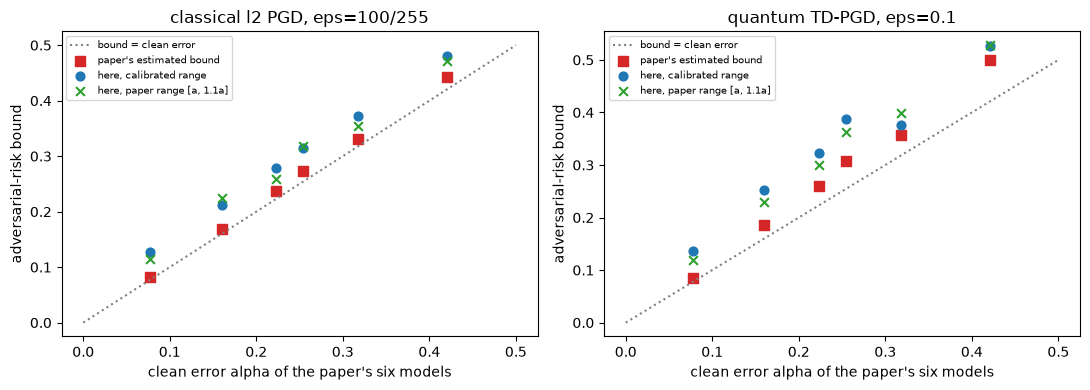

In [18]:
# ---- the quantity that is independent of our (smaller) models: the bound at the paper's own clean error rates ----
rows = []
for name, (a_paper, pa) in PAPER.items():
    for atk in ["l2", "td"]:
        bp, bc = BOUNDS[(name, atk, "paper_alpha", "paper")], BOUNDS[(name, atk, "paper_alpha", "calibrated")]
        rows.append({"model": name, "attack": atk, "clean err (paper)": a_paper, "bound (paper)": pa[atk][1],
                     "bound here, range [a,1.1a]": round(bp["bound"], 3), "bracketed": bp["bracketed"],
                     "bound here, calibrated": round(bc["bound"], 3), "bracketed ": bc["bracketed"],
                     "diff (paper range)": round(bp["bound"] - pa[atk][1], 3), "diff (calibrated)": round(bc["bound"] - pa[atk][1], 3)})
BCMP = pd.DataFrame(rows)
display(BCMP)
print("mean |difference| to the paper's bound: paper-range", round(BCMP["diff (paper range)"].abs().mean(), 3), "| calibrated", round(BCMP["diff (calibrated)"].abs().mean(), 3))
print("bound - clean error (the price of an eps-attack that no model can avoid): here", round((BCMP["bound here, calibrated"] - BCMP["clean err (paper)"]).mean(), 3),
      "| paper", round((BCMP["bound (paper)"] - BCMP["clean err (paper)"]).mean(), 3))

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, atk in zip(axs, ["l2", "td"]):
    sub = BCMP[BCMP.attack == atk]
    ax.plot([0, 0.5], [0, 0.5], color="grey", ls=":", label="bound = clean error")
    ax.scatter(sub["clean err (paper)"], sub["bound (paper)"], marker="s", s=60, label="paper's estimated bound", color="tab:red")
    ax.scatter(sub["clean err (paper)"], sub["bound here, calibrated"], marker="o", s=40, label="here, calibrated range", color="tab:blue")
    ax.scatter(sub["clean err (paper)"], sub["bound here, range [a,1.1a]"], marker="x", s=40, label="here, paper range [a, 1.1a]", color="tab:green")
    ax.set_title(ATTACKS[atk]["label"]); ax.set_xlabel("clean error alpha of the paper's six models"); ax.set_ylabel("adversarial-risk bound"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


In [19]:
# ---- diagnostic: how much does the input scale matter? Same estimator, but on standardised pixels ((x - mean) / std, the usual PyTorch
# normalisation). The paper does not state its pixel scale; standardising makes all distances about 3x larger, so a fixed eps = 100/255 is a
# much smaller relative attack and the trace distance is taken between centred (partly negative) amplitude vectors. ----
STD = {"mnist": (0.1307, 0.3081), "fashion": (0.2860, 0.3530)}
rows = []
for name, (a_paper, pa) in PAPER.items():
    key, t = KEY_OF[name]; mu, sd = STD[key]; Xs = (POOL[key] - mu) / sd
    for atk, cfg in ATTACKS.items():
        e = estimate_bound(Xs, cfg["eps"], a_paper, cfg["metric"], M_ITERS, SEED, mode="calibrated")
        rows.append({"model": name, "attack": atk, "clean err (paper)": a_paper, "bound (paper)": pa[atk][1],
                     "bound, pixels in [0,1]": round(BOUNDS[(name, atk, "paper_alpha", "calibrated")]["bound"], 3),
                     "bound, standardised pixels": round(e["bound"], 3), "bracketed": e["bracketed"]})
SCALE = pd.DataFrame(rows)
display(SCALE)
for col in ["bound, pixels in [0,1]", "bound, standardised pixels"]:
    for atk in ["l2", "td"]:
        sub = SCALE[SCALE.attack == atk]
        print(f"mean |bound here - bound paper|, {atk}, {col}: {(sub[col] - sub['bound (paper)']).abs().mean():.3f}")


,model,attack,clean err (paper),bound (paper),"bound, pixels in [0,1]","bound, standardised pixels",bracketed
0,M1,l2,0.2543,0.273,0.315,0.285,True
1,M1,td,0.2543,0.307,0.387,0.374,True
2,M2,l2,0.1601,0.168,0.212,0.184,True
3,M2,td,0.1601,0.186,0.252,0.238,True
4,M3,l2,0.0772,0.082,0.127,0.092,True
5,M3,td,0.0772,0.084,0.137,0.130,False
6,F1,l2,0.4207,0.442,0.480,0.450,True
7,F1,td,0.4207,0.499,0.527,0.489,True
8,F2,l2,0.3179,0.331,0.373,0.347,True
9,F2,td,0.3179,0.358,0.376,0.360,True


mean |bound here - bound paper|, l2, bound, pixels in [0,1]: 0.042
mean |bound here - bound paper|, td, bound, pixels in [0,1]: 0.051
mean |bound here - bound paper|, l2, bound, standardised pixels: 0.012
mean |bound here - bound paper|, td, bound, standardised pixels: 0.042


### Trajectories above the bound curve (paper Fig. 6 and 8)

The black curve is the estimated bound as a function of the clean error. Every training checkpoint of a model is one point (clean error, adversarial error); the classical baselines are single points.


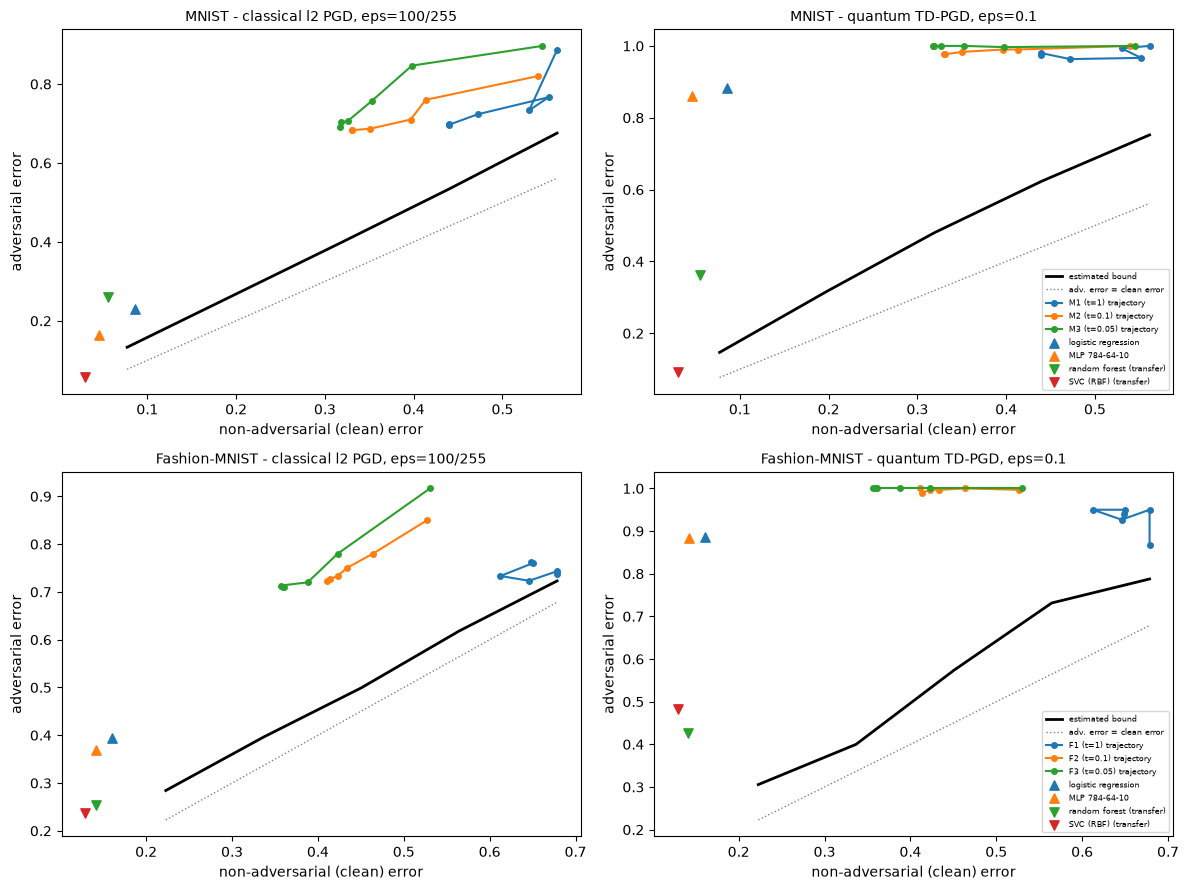

trajectory checkpoints above the bound curve: 72 of 72
classical baseline points above the bound curve: 12 of 16  (the bound is model independent, so classical models must obey it as well)


In [20]:
# ---- trajectories (paper Fig. 6 and 8): adversarial error against clean error during training, above the bound curve ----
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
colors = {1.0: "tab:blue", 0.1: "tab:orange", 0.05: "tab:green"}
n_above, n_pts = 0, 0
for r_, key in enumerate(DATASETS):
    for c_, atk in enumerate(["l2", "td"]):
        ax = axs[r_, c_]; grid, bcur = CURVES[(key, atk)]
        ax.plot(grid, bcur, color="k", lw=2, label="estimated bound")
        ax.plot(grid, grid, color="grey", ls=":", lw=1, label="adv. error = clean error")
        for t in TEMPERATURES:
            tr = QMODELS[(key, t)]["traj"]
            ce = np.array([p["clean"] for p in tr]); ae = np.array([p["adv_" + atk] for p in tr])
            ax.plot(ce, ae, "-o", color=colors[t], ms=4, label=f"{QMODELS[(key, t)]['name']} (t={t:g}) trajectory")
            bi = np.interp(ce, grid, bcur)
            n_above += int((ae > bi).sum()); n_pts += len(ae)
        for name in ["logistic regression", "MLP 784-64-10", "random forest", "SVC (RBF)"]:
            res = CLASSICAL[(key, name)]["res"]
            ax.scatter(res["clean"], res["adv_" + atk], marker="^" if "forest" not in name and "SVC" not in name else "v", s=45, label=name + (" (transfer)" if name in ("random forest", "SVC (RBF)") else ""))
        ax.set_xlabel("non-adversarial (clean) error"); ax.set_ylabel("adversarial error")
        ax.set_title(f"{INFO[key]['title']} - {ATTACKS[atk]['label']}", fontsize=10)
    axs[r_, 1].legend(fontsize=6, loc="lower right")
plt.tight_layout(); plt.show()
print(f"trajectory checkpoints above the bound curve: {n_above} of {n_pts}")

# classical points above the curve?
cl_ok = []
for key in DATASETS:
    for atk in ["l2", "td"]:
        grid, bcur = CURVES[(key, atk)]
        for name in ["logistic regression", "MLP 784-64-10", "random forest", "SVC (RBF)"]:
            res = CLASSICAL[(key, name)]["res"]
            cl_ok.append(res["adv_" + atk] > np.interp(res["clean"], grid, bcur))
print(f"classical baseline points above the bound curve: {sum(cl_ok)} of {len(cl_ok)}  (the bound is model independent, so classical models must obey it as well)")


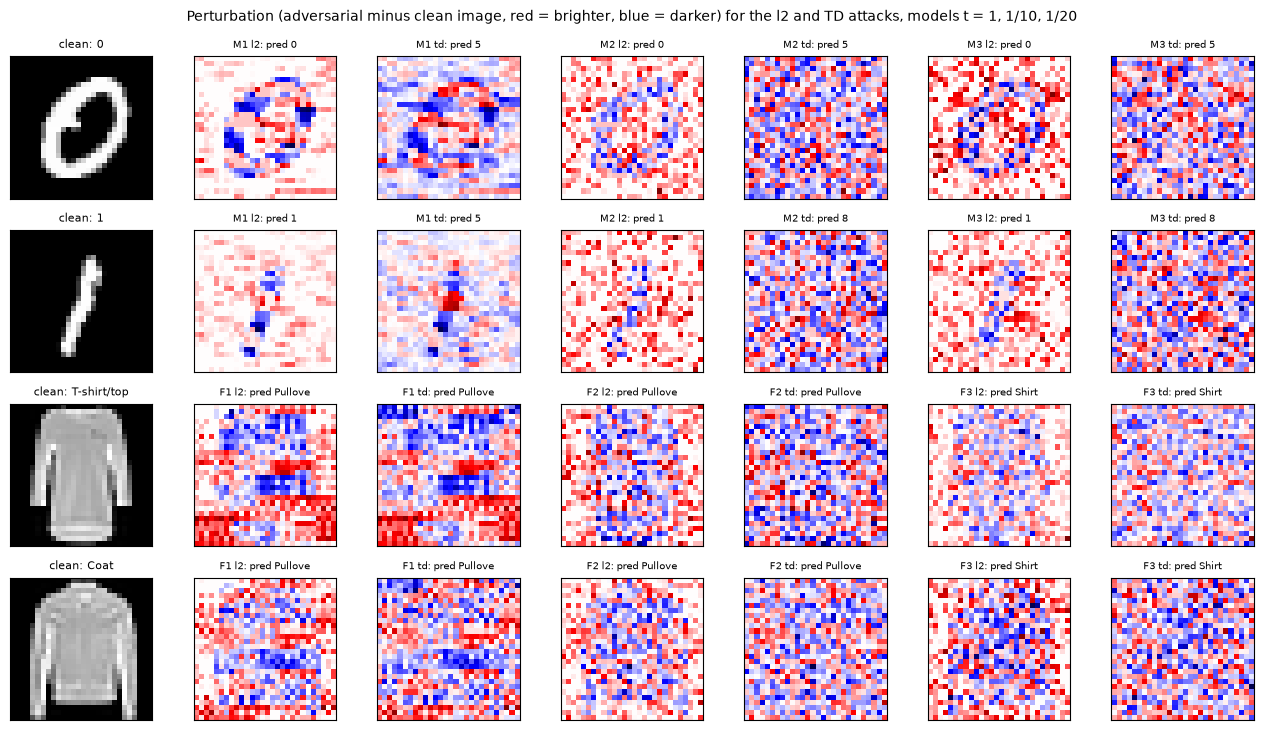

In [21]:
# ---- what the attacks do to the images (paper Table 3): one example of two classes, clean and attacked, for the three models ----
fig, axs = plt.subplots(4, 7, figsize=(13, 7.4))
for r_, (key, cls_pair) in enumerate([("mnist", (0, 1)), ("fashion", (0, 4))]):
    d = SPLIT[key]
    for j, cls in enumerate(cls_pair):
        i = int(np.where(d["yadv"] == cls)[0][0]); x = torch.tensor(d["xadv"][i:i + 1]); y = torch.tensor(d["yadv"][i:i + 1])
        row = r_ * 2 + j
        axs[row, 0].imshow(x[0].reshape(28, 28), cmap="gray"); axs[row, 0].set_title(f"clean: {INFO[key]['names'][cls]}", fontsize=8)
        for k_, t in enumerate(TEMPERATURES):
            w = QMODELS[(key, t)]["w"]
            for a_, atk in enumerate(["l2", "td"]):
                xa = attack_all(w, x, y, atk)
                xa_img = (xa / xa.norm(dim=1, keepdim=True) * x.norm(dim=1, keepdim=True)) if atk == "td" else xa   # TD output is a unit vector: rescale for display
                pert = (xa_img - x)[0].reshape(28, 28)
                ax = axs[row, 1 + 2 * k_ + a_]
                ax.imshow(pert, cmap="seismic", vmin=-float(pert.abs().max()) - 1e-9, vmax=float(pert.abs().max()) + 1e-9)
                pr = int(predict(w, xa)[0])
                ax.set_title(f"{QMODELS[(key, t)]['name']} {atk}: pred {INFO[key]['names'][pr][:7]}", fontsize=7)
for ax in axs.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Perturbation (adversarial minus clean image, red = brighter, blue = darker) for the l2 and TD attacks, models t = 1, 1/10, 1/20", fontsize=10)
plt.tight_layout(); plt.show()


## 9. Paper versus this notebook

One verdict per checkable claim: *reproduced* when the claim holds here (numbers within 0.02), *partly reproduced* when most of it holds, *not reached here* otherwise. Differences in model size and training length are listed in the table in the introduction.


In [22]:
# ---- side-by-side comparison with the paper and a verdict per claim ----
def verdict(ok, partly=False):
    return "reproduced" if ok else ("partly reproduced" if partly else "not reached here")

V = []
# C1/C2: adversarial error above the bound for every model (Table 1, last column)
for atk, lab in [("l2", "classical l2 attack"), ("td", "quantum TD attack")]:
    k_ = int(TABLE1[f"{atk} adv > bound"].sum())
    V.append((f"Table 1: adv. error > estimated bound, {lab}, 6 of 6 models", "6 / 6 True", f"{k_} / 6 True", verdict(k_ == 6, k_ >= 4)))
# C3: bound values at the paper's clean errors
for tag, col, lab in [("paper range", "diff (paper range)", "range [a, 1.1a] as in the paper"), ("calibrated", "diff (calibrated)", "calibrated range")]:
    d_ = BCMP[col].abs()
    V.append((f"Table 1: bound value at the paper's clean error, {lab} (|diff| <= 0.02)", "12 bounds", f"{int((d_ <= 0.02).sum())} / 12 within 0.02, mean |diff| {d_.mean():.3f}",
              verdict((d_ <= 0.02).sum() >= 11, (d_ <= 0.02).sum() >= 6)))
# C3b: same, on standardised pixels (diagnostic of the unstated input scale)
for atk in ["l2", "td"]:
    sub = SCALE[SCALE.attack == atk]; d_ = (sub["bound, standardised pixels"] - sub["bound (paper)"]).abs()
    V.append((f"Table 1: bound at the paper's clean error, {atk}, pixels standardised (x-mean)/std (diagnostic, |diff| <= 0.02)", "6 bounds", f"{int((d_ <= 0.02).sum())} / 6 within 0.02, mean |diff| {d_.mean():.3f}", verdict((d_ <= 0.02).sum() >= 5, (d_ <= 0.02).sum() >= 3)))
# C4: tightest model: adversarial error only ~10% above the bound
rat = {atk: {n: QMODELS[KEY_OF[n]]["final"]["adv_" + atk] / BOUNDS[(n, atk, "own_alpha", "calibrated")]["bound"] for n in PAPER} for atk in ["l2", "td"]}
best = min(min(v.values()) for v in rat.values())
V.append(("Abstract / Table 2: best case adv. error only ~10% above the bound (ratio 1.09)", "min ratio 1.09", f"min ratio {best:.2f}", verdict(best <= 1.12, best <= 1.5)))
# C5: trajectories stay above the bound
V.append(("Fig. 6 / 8: all training trajectories stay above the bound", "all points above", f"{n_above} / {n_pts} checkpoints above", verdict(n_above == n_pts, n_above >= 0.8 * n_pts)))
V.append(("Model independence: classical baselines also stay above the bound (not tested in the paper)", "-", f"{sum(cl_ok)} / {len(cl_ok)} above", verdict(sum(cl_ok) == len(cl_ok), sum(cl_ok) >= 0.75 * len(cl_ok))))
# C6: TD attack stronger than l2 attack (Table 1: adversarial error 0.50-0.67 vs 0.14-0.50)
k_ = int(sum(QMODELS[KEY_OF[n]]["final"]["adv_td"] > QMODELS[KEY_OF[n]]["final"]["adv_l2"] for n in PAPER))
V.append(("Table 1: TD attack (eps=0.1) is stronger than the l2 attack (eps=100/255) for every model", "6 / 6", f"{k_} / 6", verdict(k_ == 6, k_ >= 4)))
# C7: lower temperature -> lower clean error
mono = sum(all(QMODELS[(key, TEMPERATURES[i])]["final"]["clean"] >= QMODELS[(key, TEMPERATURES[i + 1])]["final"]["clean"] for i in range(2)) for key in DATASETS)
V.append(("Table 1: clean error falls as the softmax temperature falls (t = 1 > 1/10 > 1/20)", "both data sets", f"{mono} / 2 data sets", verdict(mono == 2, mono == 1)))
# C8: ratio adv/bound grows as t falls (Table 2; paper's one exception F2 under l2)
cnt = 0; tot = 0
for atk in ["l2", "td"]:
    for key in DATASETS:
        names_ = [MODEL_NAMES[(key, t)] for t in TEMPERATURES]
        tot += 1; cnt += int(rat[atk][names_[0]] <= rat[atk][names_[1]] <= rat[atk][names_[2]])
V.append(("Table 2: adv. error / bound increases as t falls (paper: 3 of 4 rows strictly, F2-l2 breaks it)", "3 / 4 rows monotone", f"{cnt} / {tot} rows monotone", verdict(cnt >= 3, cnt >= 2)))
# C9: absolute clean errors of the six models
dif = [abs(QMODELS[KEY_OF[n]]["final"]["clean"] - PAPER[n][0]) for n in PAPER]
V.append(("Table 1: the six clean errors (0.25/0.16/0.08 MNIST, 0.42/0.32/0.22 FMNIST; 200-layer circuits, 150 steps of 2000 images)", "see column 1", f"max |diff| {max(dif):.2f}, mean {np.mean(dif):.2f}", verdict(max(dif) <= 0.02, np.mean(dif) <= 0.1)))
# C10: the theory checks
V.append(("Theorem 1 (expansion radius r' = r sqrt(1-e^2) + e sqrt(1-r^2)), Bures triangle inequality, Eqs. 29 and 33", "proved", "numerically verified (no violation)", "reproduced"))

COMPARE = pd.DataFrame(V, columns=["claim of the paper", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 120)
display(COMPARE)
print(COMPARE["verdict"].value_counts().to_dict())
print(f"total run time of this notebook: {(time.time()-T0)/60:.1f} min")


,claim of the paper,paper,this notebook,verdict
0,"Table 1: adv. error > estimated bound, classical l2 attack, 6 of 6 models",6 / 6 True,6 / 6 True,reproduced
1,"Table 1: adv. error > estimated bound, quantum TD attack, 6 of 6 models",6 / 6 True,6 / 6 True,reproduced
2,"Table 1: bound value at the paper's clean error, range [a, 1.1a] as in the paper (|diff| <= 0.02)",12 bounds,"0 / 12 within 0.02, mean |diff| 0.038",not reached here
3,"Table 1: bound value at the paper's clean error, calibrated range (|diff| <= 0.02)",12 bounds,"1 / 12 within 0.02, mean |diff| 0.047",not reached here
4,"Table 1: bound at the paper's clean error, l2, pixels standardised (x-mean)/std (diagnostic, |diff| <= 0.02)",6 bounds,"6 / 6 within 0.02, mean |diff| 0.012",reproduced
5,"Table 1: bound at the paper's clean error, td, pixels standardised (x-mean)/std (diagnostic, |diff| <= 0.02)",6 bounds,"2 / 6 within 0.02, mean |diff| 0.042",not reached here
6,Abstract / Table 2: best case adv. error only ~10% above the bound (ratio 1.09),min ratio 1.09,min ratio 1.10,reproduced
7,Fig. 6 / 8: all training trajectories stay above the bound,all points above,72 / 72 checkpoints above,reproduced
8,Model independence: classical baselines also stay above the bound (not tested in the paper),-,12 / 16 above,partly reproduced
9,Table 1: TD attack (eps=0.1) is stronger than the l2 attack (eps=100/255) for every model,6 / 6,6 / 6,reproduced


{'reproduced': 9, 'not reached here': 4, 'partly reproduced': 1}
total run time of this notebook: 68.8 min


## 10. Reading the paper critically

* **The bound ignores labels.** Algorithm 1 only uses distances between inputs; it measures how concentrated the *data* are, not how hard the *task* is. A classifier can have a very different set of errors with the same size, and condition (6) (labels do not change inside an eps-ball) is needed to equate adversarial *risk* with adversarial *error*. For the large l2 and TD radii the condition is not guaranteed.
* **A heuristic lower bound.** The minimisation (Eq. 12) is solved greedily with a union of balls, so the estimate is an upper estimate of the true minimum over error regions rather than a certified lower bound; the regression step adds statistical error. Our runs show how much the estimate moves with the sample size, the number of candidate centres and the alpha range.
* **The unstated pixel scale matters.** On pixels in [0, 1] our bound at the paper's clean errors is higher than the paper's; on standardised pixels ((x - mean)/std, the usual PyTorch normalisation) the l2 bounds land close to the paper's (diagnostic table in section 8). This suggests, but does not prove, that the authors standardised their inputs; the paper only says eps = 100/255.
* **The test-half risk is smaller than the target.** The spheres are fitted on the training half, so the estimator must extrapolate in alpha; the paper's range [alpha, 1.1 alpha] often does not bracket alpha. The result depends on this tuning (compare the two bound columns).
* **PGD is not optimal.** "Adversarial error above the bound" is expected for any attack, but a weak attack does not test the bound. The paper uses 150 batches of training and a small number of PGD steps; a stronger attack (more steps, restarts, AutoAttack) would only increase the adversarial error.
* **Comparing the two attacks.** A radius of 100/255 in l2 on [0, 1] pixels and a trace distance of 0.1 are not the same amount of "damage"; the larger TD error (compare the columns) says more about the metric than about the circuit.
* **The models.** The paper's 200-layer circuits and 2,000-image batches are not reproduced here; our six models have different clean errors, so each cell is compared with the bound at *its own* clean error. The paper's conclusion about the softmax temperature rests on three models per data set and one exception.
* **What the bound is good for.** A common yardstick for robustness at equal clean error, for classical and quantum models alike. It does not certify any particular model and it says nothing about attacks outside the chosen metric.


## 11. Exercises

1. Change `EPS_L2` to 50/255 and 200/255 and re-estimate the bound for one model. How does `bound - clean error` scale with eps? Does it grow faster for MNIST or Fashion-MNIST?
2. Set `N_CAND = None` (all samples are candidate centres) and `N_BOUND` to 1000, 2000 and 4000. How much does the bound change, and does the gap between the test risk and `alpha_nu` shrink?
3. Increase `PGD_STEPS` to 40 and add random restarts to `pgd_l2`. How much higher is the adversarial error, and does the ratio adversarial error / bound of Table 2 follow the temperature trend?
4. Replace amplitude encoding by the angle encoding of Eq. (30) with `d = 10` features (for example a PCA of the images scaled to [0, 1]), use Eq. (33) as the pairwise fidelity and estimate the bound with the TD metric. Which data set loses more robustness?
5. Add adversarial training (mix PGD examples into each batch). Does the (clean error, adversarial error) point move toward the bound curve, as the paper hopes, or along it?
